# Chương 5 — Thực nghiệm mở rộng

Chương này đánh giá khả năng mở rộng ngoài mẫu của Diffusion Maps trên Swiss Roll và MNIST. Diffusion Maps đầy đủ được dùng làm tham chiếu; Nyström và NeuralEF được đánh giá về độ trung thực hình học và chi phí tính toán.


## Thiết lập thư viện và môi trường


In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import cm
from sklearn.datasets import make_swiss_roll
from tensorflow.keras.datasets import mnist
from sklearn.metrics import pairwise_distances
from scipy.linalg import eigh
from scipy.spatial import procrustes
from scipy.stats import spearmanr, pearsonr
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin
import time
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
_pics = '/content/pictures'
os.makedirs(_pics, exist_ok=True)
print("All imports successful.")


Device: cuda
All imports successful.


---
## 5.1. Bài toán mở rộng của Diffusion Maps

Diffusion Maps đầy đủ cần phân rã ma trận kích thước $N\times N$, với chi phí thời gian $\mathcal{O}(N^3)$ và bộ nhớ $\mathcal{O}(N^2)$. Thực nghiệm khảo sát hai cơ chế mở rộng:

- **Nyström:** xấp xỉ phổ từ tập landmark và ánh xạ mẫu mới bằng nội suy kernel.
- **NeuralEF:** học hàm tham số hóa để dự đoán các hàm riêng khuếch tán.

Hai phương pháp được so sánh với cùng biểu diễn tham chiếu và cùng giao thức đánh giá.


---
## 5.2. Xấp xỉ Nyström

Với $m$ landmark, Nyström phân rã khối kernel $K_{mm}$ và mở rộng các vectơ riêng sang toàn bộ dữ liệu:

$$K_{mm}^{\mathrm{sym}}=D_m^{-1/2}K_{mm}D_m^{-1/2}=U_m\Lambda_mU_m^\top,$$

$$\widehat{\Phi}=\widetilde{K}_{nm}U_m\Lambda_m^{-1}.$$

Chi phí tính toán giảm còn $\mathcal{O}(m^2N+m^3)$ khi $m\ll N$.

### Cài đặt thuật toán


In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# Full Diffusion Map (ground truth baseline)
# ─────────────────────────────────────────────────────────────────────────────

def full_diffusion_map(X, epsilon="auto", t=1, n_components=2):
    """Full eigendecomposition Diffusion Map — O(N^3) ground truth."""
    N = X.shape[0]
    dist_sq = pairwise_distances(X, metric='sqeuclidean')
    if epsilon == "auto":
        triu_idx = np.triu_indices(N, k=1)
        epsilon = max(np.median(dist_sq[triu_idx]), 1e-10)
    K = np.exp(-dist_sq / epsilon)
    degree = K.sum(axis=1)
    d_inv_sqrt = 1.0 / np.sqrt(degree)
    K_sym = d_inv_sqrt[:, None] * K * d_inv_sqrt[None, :]
    eigenvalues, eigenvectors = eigh(K_sym)
    idx = np.argsort(-eigenvalues)
    eigenvalues, eigenvectors = eigenvalues[idx], eigenvectors[:, idx]
    coords = eigenvectors[:, 1:n_components+1] * (eigenvalues[1:n_components+1] ** t)
    return coords, eigenvalues, eigenvectors, epsilon


# ─────────────────────────────────────────────────────────────────────────────
# Landmark selection
# ─────────────────────────────────────────────────────────────────────────────

def select_landmarks(X, m, method="kmeans"):
    """Select m landmarks: 'random', 'kmeans', or 'farthest'."""
    N = X.shape[0]
    if method == "random":
        idx = np.random.choice(N, m, replace=False)
        return X[idx], idx
    elif method == "kmeans":
        km = KMeans(n_clusters=m, random_state=42, n_init=3)
        km.fit(X)
        idx = pairwise_distances_argmin(km.cluster_centers_, X)
        return X[idx], idx
    elif method == "farthest":
        idx = [np.random.randint(N)]
        min_dists = pairwise_distances(X[idx], X, metric='sqeuclidean').flatten()
        for _ in range(m - 1):
            next_idx = int(np.argmax(min_dists))
            idx.append(next_idx)
            new_dists = pairwise_distances(X[next_idx:next_idx+1], X, metric='sqeuclidean').flatten()
            min_dists = np.minimum(min_dists, new_dists)
        return X[np.array(idx)], np.array(idx)


# ─────────────────────────────────────────────────────────────────────────────
# Nyström Diffusion Map — O(m²N + m³)
# ─────────────────────────────────────────────────────────────────────────────

def nystrom_diffusion_map(X, m=100, t=1, n_components=2,
                          epsilon="auto", landmark_method="kmeans"):
    """
    Nyström approximation of Diffusion Map.
    Cost: O(m²N + m³) instead of O(N³).
    """
    N = X.shape[0]
    landmarks, landmark_idx = select_landmarks(X, m, method=landmark_method)
    dist_mm = pairwise_distances(landmarks, landmarks, metric='sqeuclidean')
    if epsilon == "auto":
        triu_idx = np.triu_indices(m, k=1)
        epsilon = max(np.median(dist_mm[triu_idx]), 1e-10)
    K_mm = np.exp(-dist_mm / epsilon)
    dist_nm = pairwise_distances(X, landmarks, metric='sqeuclidean')
    K_nm = np.exp(-dist_nm / epsilon)

    degree_m = K_mm.sum(axis=1)
    d_inv_sqrt_m = 1.0 / np.sqrt(degree_m + 1e-10)
    K_mm_sym = d_inv_sqrt_m[:, None] * K_mm * d_inv_sqrt_m[None, :]
    evals_m, evecs_m = eigh(K_mm_sym)
    idx_sort = np.argsort(-evals_m)
    evals_m, evecs_m = evals_m[idx_sort], evecs_m[:, idx_sort]

    degree_approx = K_nm.sum(axis=1) * (N / m)
    d_inv_sqrt_all = 1.0 / np.sqrt(degree_approx + 1e-10)
    K_nm_tilde = d_inv_sqrt_all[:, None] * K_nm * d_inv_sqrt_m[None, :]

    k = min(n_components + 1, len(evals_m))
    evals_top, evecs_top = evals_m[:k], evecs_m[:, :k]
    inv_evals = 1.0 / np.maximum(evals_top, 1e-10)
    nystrom_evecs = K_nm_tilde @ evecs_top @ np.diag(inv_evals)
    coords = nystrom_evecs[:, 1:n_components+1] * (evals_top[1:n_components+1] ** t)

    info = {"epsilon": epsilon, "eigenvalues_landmarks": evals_m,
            "eigenvectors_landmarks": evecs_m, "K_mm": K_mm,
            "d_inv_sqrt_m": d_inv_sqrt_m}
    return coords, landmarks, landmark_idx, info


def nystrom_out_of_sample(X_new, landmarks, info, t=1, n_components=2):
    """Embed new points via precomputed landmark eigenstructure — O(m) per point."""
    epsilon = info["epsilon"]
    evals_m, evecs_m = info["eigenvalues_landmarks"], info["eigenvectors_landmarks"]
    d_inv_sqrt_m = info["d_inv_sqrt_m"]
    dist_new = pairwise_distances(X_new, landmarks, metric='sqeuclidean')
    K_new = np.exp(-dist_new / epsilon)
    d_inv_sqrt_new = 1.0 / np.sqrt(K_new.sum(axis=1) + 1e-10)
    K_new_tilde = d_inv_sqrt_new[:, None] * K_new * d_inv_sqrt_m[None, :]
    k = min(n_components + 1, len(evals_m))
    evals_top, evecs_top = evals_m[:k], evecs_m[:, :k]
    inv_evals = 1.0 / np.maximum(evals_top, 1e-10)
    nystrom_evecs_new = K_new_tilde @ evecs_top @ np.diag(inv_evals)
    return nystrom_evecs_new[:, 1:n_components+1] * (evals_top[1:n_components+1] ** t)


# ─────────────────────────────────────────────────────────────────────────────
# Quality metrics
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_quality(coords_full, coords_approx, n_sample=500):
    """Procrustes disparity + Spearman pairwise-distance correlation."""
    _, _, disparity = procrustes(
        coords_full / np.linalg.norm(coords_full),
        coords_approx / np.linalg.norm(coords_approx)
    )
    n = min(n_sample, len(coords_full))
    idx = np.random.choice(len(coords_full), n, replace=False)
    triu = np.triu_indices(n, k=1)
    corr, _ = spearmanr(
        pairwise_distances(coords_full[idx])[triu],
        pairwise_distances(coords_approx[idx])[triu]
    )
    return disparity, corr

def pairwise_rank_corr(coords_pred, coords_gt, n_sample=300):
    n = min(n_sample, len(coords_pred))
    idx = np.random.choice(len(coords_pred), n, replace=False)
    triu = np.triu_indices(n, k=1)
    corr, _ = spearmanr(
        pairwise_distances(coords_pred[idx])[triu],
        pairwise_distances(coords_gt[idx])[triu]
    )
    return corr


# ─────────────────────────────────────────────────────────────────────────────
# Generate Swiss Roll (N=2000) and compute Full DM ground truth
# ─────────────────────────────────────────────────────────────────────────────

N = 2000
X_swiss, color_swiss = make_swiss_roll(n_samples=N, noise=0.5, random_state=42)

t0 = time.time()
coords_full, evals_full, evecs_full, eps_full = full_diffusion_map(X_swiss, t=1)
time_full = time.time() - t0

print(f"Full Diffusion Map: N={N}, ε={eps_full:.4f}, time={time_full:.2f}s")
print(f"Top-6 eigenvalues: {evals_full[:6].round(4)}")


Full Diffusion Map: N=2000, ε=229.5154, time=1.39s
Top-6 eigenvalues: [1.     0.3645 0.311  0.2739 0.0996 0.0886]


---
## 5.3. Đánh giá Nyström

### 5.3.1. Ảnh hưởng của số landmark

Hình so sánh Diffusion Maps đầy đủ với Nyström trên Swiss Roll tại $m\in\{50,100,200,500\}$.


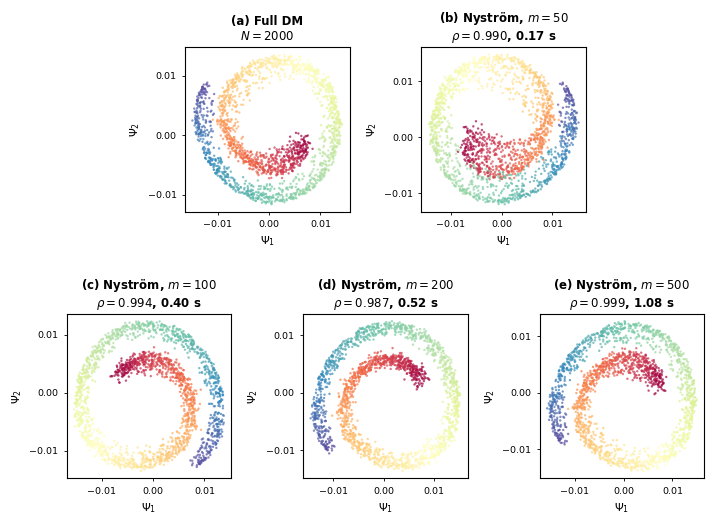

Đã lưu: /content/pictures/fig_nystrom_comparison.pdf


In [8]:
# ── Nyström vs Full DM for m = 50, 100, 200, 500 ───────────────

m_values = [50, 100, 200, 500]

fig = plt.figure(figsize=(7.2, 5.6))
gs = fig.add_gridspec(2, 6)

axes = [
    fig.add_subplot(gs[0, 1:3]),
    fig.add_subplot(gs[0, 3:5]),
    fig.add_subplot(gs[1, 0:2]),
    fig.add_subplot(gs[1, 2:4]),
    fig.add_subplot(gs[1, 4:6])
]

panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)']

ax = axes[0]
ax.scatter(coords_full[:, 0], coords_full[:, 1], c=color_swiss, cmap='Spectral', s=3, alpha=0.7, linewidths=0, rasterized=True)
ax.set_title(f'{panel_labels[0]} Full DM\n$N={N}$', fontsize=8.5, fontweight='bold', pad=5)
ax.set_xlabel(r'$\Psi_1$', fontsize=8)
ax.set_ylabel(r'$\Psi_2$', fontsize=8)

for i, m in enumerate(m_values):
    t0 = time.time()
    coords_nys, landmarks, lm_idx, info_nys = nystrom_diffusion_map(X_swiss, m=m, t=1, epsilon=eps_full, landmark_method='kmeans')
    elapsed = time.time() - t0
    _, corr = evaluate_quality(coords_full, coords_nys)

    ax = axes[i + 1]
    ax.scatter(coords_nys[:, 0], coords_nys[:, 1], c=color_swiss, cmap='Spectral', s=3, alpha=0.7, linewidths=0, rasterized=True)
    ax.set_title(f'{panel_labels[i + 1]} Nyström, $m={m}$\n$\\rho={corr:.3f}$, {elapsed:.2f} s', fontsize=8.5, fontweight='bold', pad=5)
    ax.set_xlabel(r'$\Psi_1$', fontsize=8)
    ax.set_ylabel(r'$\Psi_2$', fontsize=8)

for ax in axes:
    ax.set_box_aspect(1)
    ax.tick_params(axis='both', labelsize=6.8, length=2.5, width=0.6)
    ax.locator_params(axis='both', nbins=4)

fig.subplots_adjust(left=0.07, right=0.985, bottom=0.09, top=0.86, wspace=0.75, hspace=0.62)
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_nystrom_comparison.pdf', dpi=300, bbox_inches='tight', pad_inches=0.03, facecolor='white')
plt.show()

print(f'Đã lưu: {_pics}/fig_nystrom_comparison.pdf')

### 5.3.2. Chất lượng và thời gian tính toán

Hình đánh giá ba chiến lược chọn landmark bằng sai lệch Procrustes, tương quan Spearman và thời gian thực thi.


  random: done
  kmeans: done
  farthest: done


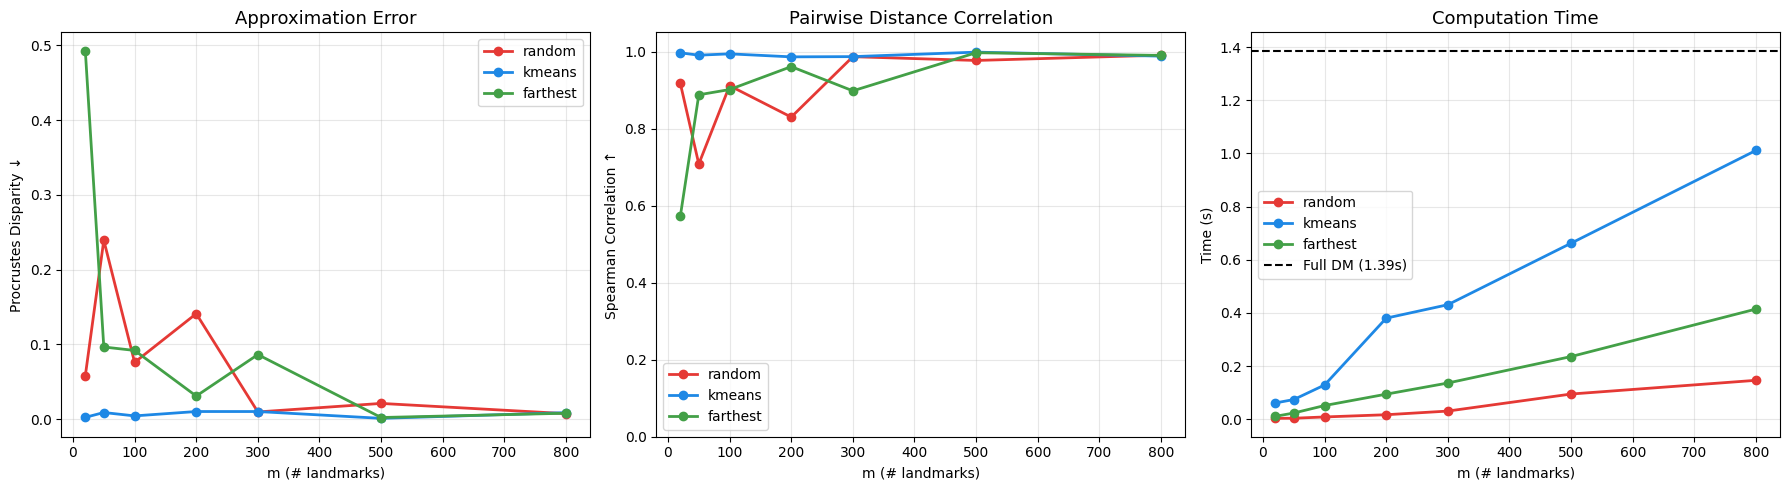

In [10]:
# ── Quality vs landmark count for three selection strategies ────────

m_test = [20, 50, 100, 200, 300, 500, 800]
landmark_methods = ["random", "kmeans", "farthest"]
colors_method = {"random": "#E53935", "kmeans": "#1E88E5", "farthest": "#43A047"}

results = {met: {"m": [], "error": [], "corr": [], "time": []} for met in landmark_methods}
for method in landmark_methods:
    for m in m_test:
        if m >= N:
            continue
        t0 = time.time()
        coords_nys_q, _, _, _ = nystrom_diffusion_map(
            X_swiss, m=m, t=1, epsilon=eps_full, landmark_method=method)
        elapsed = time.time() - t0
        err, corr = evaluate_quality(coords_full, coords_nys_q)
        results[method]["m"].append(m)
        results[method]["error"].append(err)
        results[method]["corr"].append(corr)
        results[method]["time"].append(elapsed)
    print(f"  {method}: done")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for method in landmark_methods:
    r = results[method]
    c = colors_method[method]
    axes[0].plot(r["m"], r["error"], "o-", label=method, color=c, linewidth=2)
    axes[1].plot(r["m"], r["corr"],  "o-", label=method, color=c, linewidth=2)
    axes[2].plot(r["m"], r["time"],  "o-", label=method, color=c, linewidth=2)

axes[0].set_xlabel("m (# landmarks)"); axes[0].set_ylabel("Procrustes Disparity ↓")
axes[0].set_title("Approximation Error", fontsize=13); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel("m (# landmarks)"); axes[1].set_ylabel("Spearman Correlation ↑")
axes[1].set_title("Pairwise Distance Correlation", fontsize=13)
axes[1].set_ylim(0, 1.05); axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[2].set_xlabel("m (# landmarks)"); axes[2].set_ylabel("Time (s)")
axes[2].set_title("Computation Time", fontsize=13)
axes[2].axhline(y=time_full, color="black", linestyle="--", label=f"Full DM ({time_full:.2f}s)")
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_nystrom_quality_speed.pdf', bbox_inches='tight')
plt.show()


### 5.3.3. Ánh xạ ngoài mẫu

Nyström ánh xạ mẫu mới bằng cấu trúc riêng đã ước lượng từ tập landmark mà không phân rã lại toàn bộ ma trận. Hình trình bày thời gian và độ phù hợp với biểu diễn tham chiếu.


OOS extension: 500 new points in 0.0024s (0.00ms/point)
Spearman ρ = 0.947,  Procrustes disparity = 0.0422


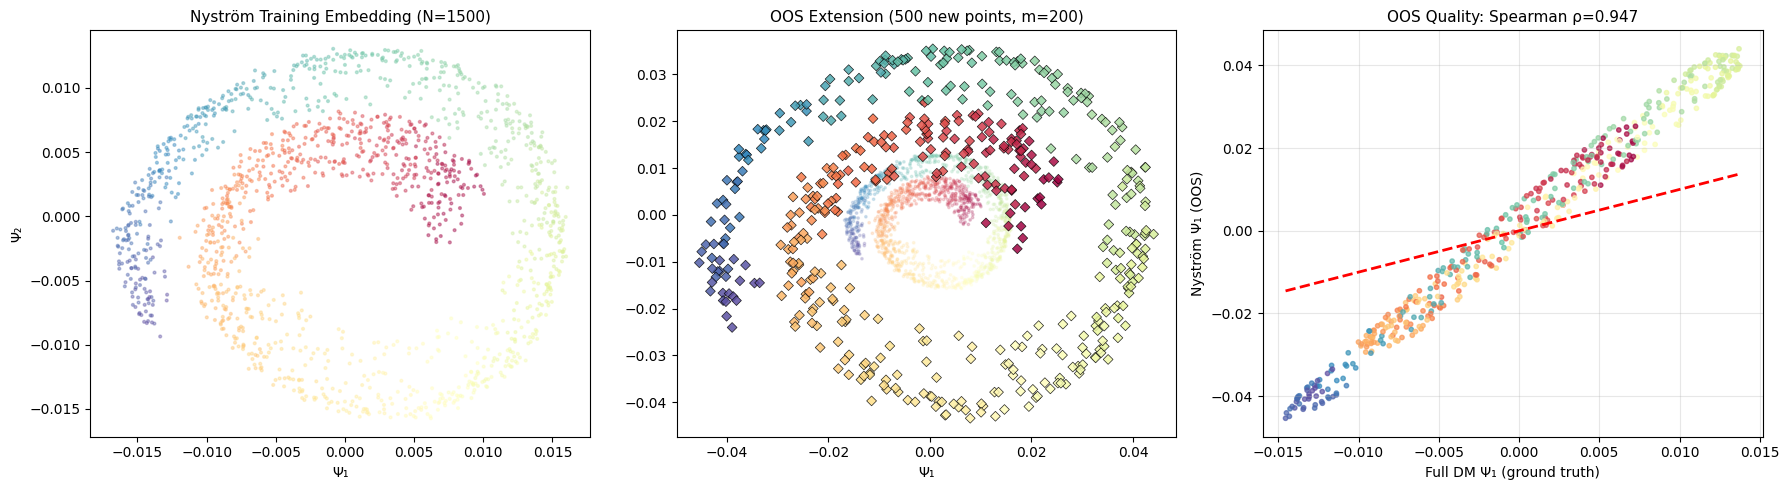

In [11]:
# ── Fig Nyström Out-of-Sample Extension ────────────────────────────────

N_train_oos, N_test_oos = 1500, 500
X_train_oos = X_swiss[:N_train_oos];  color_train_oos = color_swiss[:N_train_oos]
X_test_oos  = X_swiss[N_train_oos:];  color_test_oos  = color_swiss[N_train_oos:]
coords_test_gt = coords_full[N_train_oos:]

m_oos = 200
coords_nys_train, lm_oos, lm_idx_oos, info_oos = nystrom_diffusion_map(
    X_train_oos, m=m_oos, t=1, landmark_method="kmeans")

t0 = time.time()
coords_nys_test = nystrom_out_of_sample(X_test_oos, lm_oos, info_oos, t=1)
oos_time = time.time() - t0

err_oos, corr_oos = evaluate_quality(coords_test_gt, coords_nys_test)
print(f"OOS extension: {N_test_oos} new points in {oos_time:.4f}s ({oos_time/N_test_oos*1000:.2f}ms/point)")
print(f"Spearman ρ = {corr_oos:.3f},  Procrustes disparity = {err_oos:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.scatter(coords_nys_train[:, 0], coords_nys_train[:, 1], c=color_train_oos, cmap='Spectral', s=4, alpha=0.4)
ax.set_title(f'Nyström Training Embedding (N={N_train_oos})', fontsize=11)
ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

ax = axes[1]
ax.scatter(coords_nys_train[:, 0], coords_nys_train[:, 1], c=color_train_oos, cmap='Spectral', s=3, alpha=0.2)
ax.scatter(coords_nys_test[:, 0], coords_nys_test[:, 1], c=color_test_oos, cmap='Spectral',
           s=25, alpha=0.85, edgecolors='black', linewidths=0.5, marker='D')
ax.set_title(f'OOS Extension ({N_test_oos} new points, m={m_oos})', fontsize=11)
ax.set_xlabel('Ψ₁')

ax = axes[2]
ax.scatter(coords_test_gt[:, 0], coords_nys_test[:, 0], c=color_test_oos, cmap='Spectral', s=10, alpha=0.7)
ax.plot([coords_test_gt[:, 0].min(), coords_test_gt[:, 0].max()],
        [coords_test_gt[:, 0].min(), coords_test_gt[:, 0].max()], 'r--', linewidth=2)
ax.set_xlabel('Full DM Ψ₁ (ground truth)'); ax.set_ylabel('Nyström Ψ₁ (OOS)')
ax.set_title(f'OOS Quality: Spearman ρ={corr_oos:.3f}', fontsize=11); ax.grid(True, alpha=0.3)
plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_nystrom_oos.pdf', bbox_inches='tight')
plt.show()


### 5.3.4. Miền hiệu lực

Nyström là phương pháp nội suy. Độ tin cậy giảm khi mẫu mới nằm ngoài vùng được tập landmark bao phủ. Minh họa trường hợp cùng đa tạp và trường hợp ngoài phân phối.


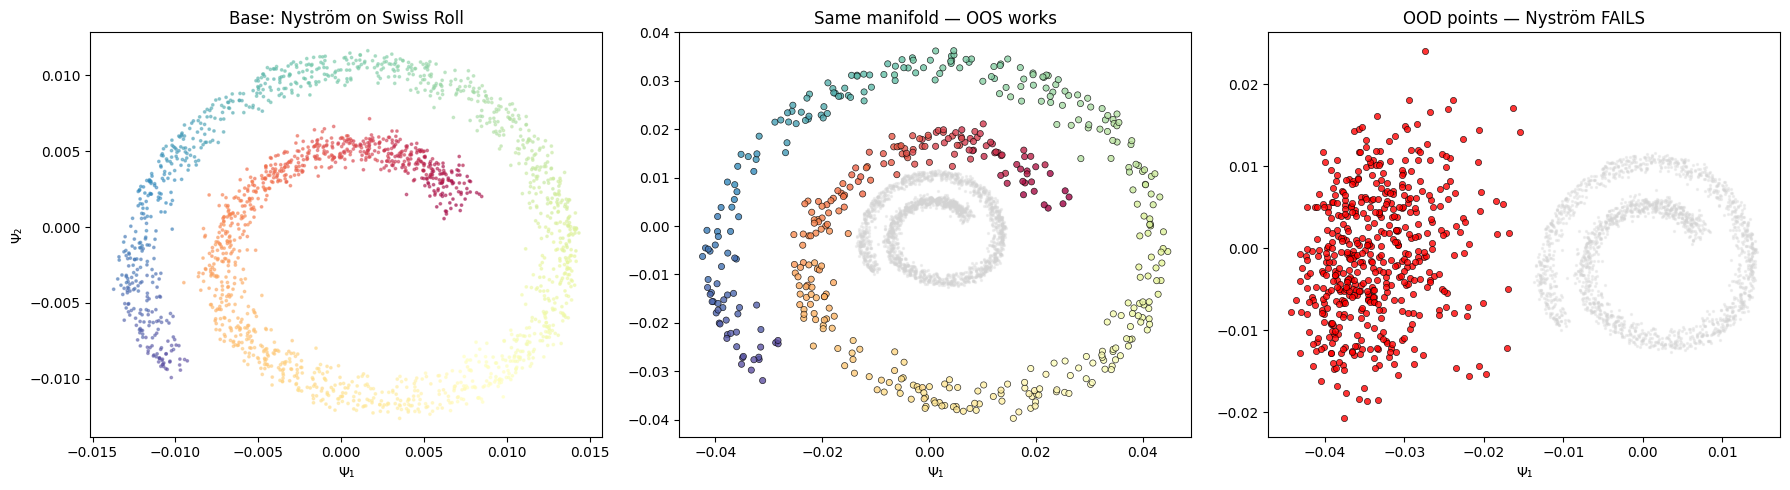

In [12]:
# ── Nyström OOS — same-manifold vs out-of-distribution ─────────────

X_same, c_same = make_swiss_roll(n_samples=500, noise=0.5, random_state=99)
X_diff = np.random.randn(500, 3) * 3 + np.array([10, 0, 10])  # OOD cloud

coords_base, lm_base, _, info_base = nystrom_diffusion_map(
    X_swiss, m=200, t=1, landmark_method="kmeans")
coords_same_ext = nystrom_out_of_sample(X_same, lm_base, info_base, t=1)
coords_diff_ext = nystrom_out_of_sample(X_diff, lm_base, info_base, t=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.scatter(coords_base[:, 0], coords_base[:, 1], c=color_swiss, cmap='Spectral', s=3, alpha=0.5)
ax.set_title('Base: Nyström on Swiss Roll', fontsize=12); ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

ax = axes[1]
ax.scatter(coords_base[:, 0], coords_base[:, 1], c='lightgray', s=2, alpha=0.3)
ax.scatter(coords_same_ext[:, 0], coords_same_ext[:, 1], c=c_same, cmap='Spectral',
           s=20, edgecolors='black', linewidths=0.5, alpha=0.8)
ax.set_title('Same manifold — OOS works', fontsize=12); ax.set_xlabel('Ψ₁')

ax = axes[2]
ax.scatter(coords_base[:, 0], coords_base[:, 1], c='lightgray', s=2, alpha=0.3)
ax.scatter(coords_diff_ext[:, 0], coords_diff_ext[:, 1], c='red',
           s=20, edgecolors='black', linewidths=0.5, alpha=0.8)
ax.set_title('OOD points — Nyström FAILS', fontsize=12); ax.set_xlabel('Ψ₁')

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_nystrom_failure_case.pdf', bbox_inches='tight')
plt.show()

### 5.3.5. Khả năng mở rộng theo kích thước dữ liệu

So sánh thời gian và tương quan Spearman của hai phương pháp với $m=200$ và $N\in\{500,1000,2000,5000,10000\}$. Các giá trị được tính trực tiếp khi thực thi notebook.



       N  Full DM (s)  Nyström (s)    Speedup   Spearman ρ
──────────────────────────────────────────────────────────
     500         0.31         0.32       1.0x        0.964
    1000         0.44         0.74       0.6x        0.934
    2000         5.16         0.61       8.5x        0.987
    5000        25.37         0.44      58.3x        0.976
   10000            —         0.95          —            —


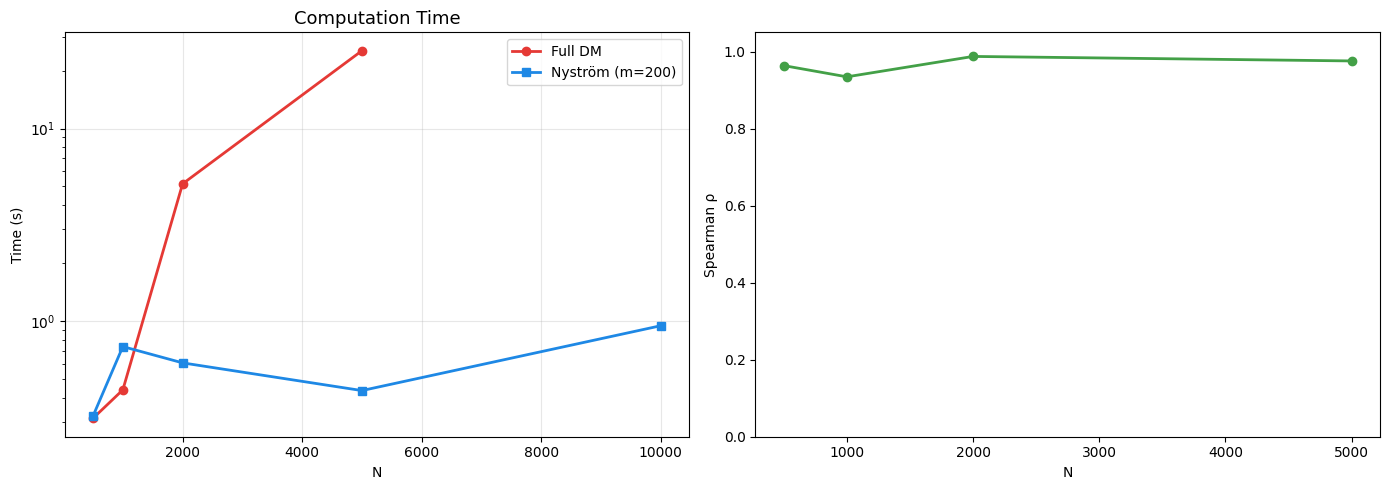

In [13]:
# ── Scalability benchmark ──────────────────────────────

N_values   = [500, 1000, 2000, 5000, 10000]
m_fixed    = 200
t_full_l, t_nys_l, corr_l = [], [], []

for Nv in N_values:
    Xv, _ = make_swiss_roll(n_samples=Nv, noise=0.5, random_state=42)
    if Nv <= 5000:
        t0 = time.time()
        cf, _, _, ep = full_diffusion_map(Xv, t=1)
        t_full_l.append(time.time() - t0)
    else:
        cf, ep = None, "auto"
        t_full_l.append(float('nan'))

    t0 = time.time()
    cn, _, _, _ = nystrom_diffusion_map(Xv, m=min(m_fixed, Nv-1), t=1, landmark_method="kmeans")
    t_nys_l.append(time.time() - t0)

    if cf is not None:
        _, corr = evaluate_quality(cf, cn)
        corr_l.append(corr)
    else:
        corr_l.append(float('nan'))

# Table
print(f"\n{'N':>8} {'Full DM (s)':>12} {'Nyström (s)':>12} {'Speedup':>10} {'Spearman ρ':>12}")
print("─" * 58)
for i, Nv in enumerate(N_values):
    tf = t_full_l[i]; tn = t_nys_l[i]; corr = corr_l[i]
    sp = f"{tf/tn:.1f}x" if not np.isnan(tf) else "—"
    c  = f"{corr:.3f}"  if not np.isnan(corr) else "—"
    tf_s = f"{tf:.2f}" if not np.isnan(tf) else "—"
    print(f"{Nv:>8} {tf_s:>12} {tn:>12.2f} {sp:>10} {c:>12}")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
valid = [i for i, v in enumerate(t_full_l) if not np.isnan(v)]
ax1.plot([N_values[i] for i in valid], [t_full_l[i] for i in valid],
         'o-', label='Full DM', linewidth=2, color='#E53935')
ax1.plot(N_values, t_nys_l, 's-', label=f'Nyström (m={m_fixed})', linewidth=2, color='#1E88E5')
ax1.set_xlabel('N'); ax1.set_ylabel('Time (s)'); ax1.set_yscale('log')
ax1.set_title('Computation Time', fontsize=13); ax1.legend(); ax1.grid(True, alpha=0.3)

valid_c = [i for i, v in enumerate(corr_l) if not np.isnan(v)]
ax2.plot([N_values[i] for i in valid_c], [corr_l[i] for i in valid_c],
         'o-', linewidth=2, color='#43A047')
ax2.set_xlabel('N'); ax2.set_ylabel('Spearman ρ'); ax2.set_ylim(0, 1.05)
plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_nystrom_scalability.pdf', bbox_inches='tight')
plt.show()


---
## 5.4. Xấp xỉ hàm riêng bằng mạng thần kinh

NeuralEF học ánh xạ

$$f_\theta(x)=\left[\widehat{\phi}_1(x),\ldots,\widehat{\phi}_K(x)\right]$$

từ mục tiêu Rayleigh và ràng buộc trực giao. Sau huấn luyện, mẫu mới được xử lý bằng một lần truyền xuôi qua mạng.

### 5.4.1. NeuralEF v1


In [14]:
# ── NeuralEF v1: Model, Loss, Training ──────────────────────────────────────

class NeuralEigenfunction(nn.Module):
    """MLP approximating top-K eigenfunctions of a diffusion kernel."""
    def __init__(self, input_dim, n_eigenfunctions=2, hidden_dims=[256, 256, 128]):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_eigenfunctions))
        self.net = nn.Sequential(*layers)
        self.n_eigenfunctions = n_eigenfunctions

    def forward(self, x):
        return self.net(x)


class NeuralEFLoss(nn.Module):
    """SpIN-style loss: maximize Rayleigh quotient + enforce orthogonality."""
    def __init__(self, mu=10.0):
        super().__init__(); self.mu = mu

    def forward(self, F, K_batch):
        B, K = F.shape
        F_norm = F / (F.norm(dim=0, keepdim=True) + 1e-8) * (B ** 0.5)
        G = F_norm.T @ F_norm / B
        rayleigh = torch.trace(F_norm.T @ K_batch @ F_norm) / (B * B)
        orth = ((G - torch.eye(K, device=F.device)) ** 2).sum()
        evals_est = torch.diag(F_norm.T @ K_batch @ F_norm).detach() / (B * B)
        return -rayleigh + self.mu * orth, {
            "rayleigh": rayleigh.item(), "orth_penalty": orth.item(),
            "eigenvalues_est": evals_est.cpu().numpy()}


def compute_diffusion_kernel_batch(X_batch, epsilon):
    dist_sq = torch.cdist(X_batch, X_batch, p=2) ** 2
    K = torch.exp(-dist_sq / epsilon)
    deg = K.sum(dim=1)
    d = 1.0 / torch.sqrt(deg + 1e-10)
    return d.unsqueeze(1) * K * d.unsqueeze(0)


def train_neural_ef_v1(X_data, epsilon, n_eigenfunctions=2,
                       batch_size=256, n_epochs=300, lr=1e-3, mu=10.0):
    N, D = X_data.shape
    X_t = torch.FloatTensor(X_data).to(device)
    loader = DataLoader(TensorDataset(X_t), batch_size=batch_size, shuffle=True, drop_last=True)
    model = NeuralEigenfunction(D, n_eigenfunctions, [256, 256, 128]).to(device)
    crit = NeuralEFLoss(mu)
    opt  = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    hist = {"loss": [], "rayleigh": [], "orth": [], "evals": []}
    for epoch in range(n_epochs):
        eloss = 0; nb = 0
        model.train()
        for (Xb,) in loader:
            Kb = compute_diffusion_kernel_batch(Xb, epsilon)
            F  = model(Xb)
            loss, info = crit(F, Kb)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); eloss += loss.item(); nb += 1
        sched.step()
        hist["loss"].append(eloss / nb)
        if (epoch + 1) % 50 == 0 or epoch == 0:
            model.eval()
            with torch.no_grad():
                idx = torch.randperm(N)[:min(512, N)]
                _, ei = crit(model(X_t[idx]), compute_diffusion_kernel_batch(X_t[idx], epsilon))
                hist["evals"].append(ei["eigenvalues_est"])
            model.train()
            print(f"  v1 Epoch {epoch+1:3d}/{n_epochs}  loss={eloss/nb:.4f}  "
                  f"λ_est={ei['eigenvalues_est'].round(4)}")
    return model, hist


print("Training NeuralEF v1 (SpIN objective) on Swiss Roll (N=2000)...")
t0 = time.time()
model_v1, hist_v1 = train_neural_ef_v1(X_swiss, eps_full, n_eigenfunctions=2,
                                        batch_size=256, n_epochs=300, lr=1e-3, mu=10.0)
time_v1 = time.time() - t0
print(f"Training time: {time_v1:.1f}s")

model_v1.eval()
with torch.no_grad():
    coords_v1 = model_v1(torch.FloatTensor(X_swiss).to(device)).cpu().numpy()

err_v1, corr_v1 = evaluate_quality(coords_full, coords_v1)
print(f"\nNeuralEF v1:  Procrustes={err_v1:.4f},  Spearman ρ={corr_v1:.4f}")
print(f"Nyström m=200: computed earlier")


Training NeuralEF v1 (SpIN objective) on Swiss Roll (N=2000)...
  v1 Epoch   1/300  loss=2.8694  λ_est=[0.0006 0.0007]
  v1 Epoch  50/300  loss=-0.0030  λ_est=[0.0009 0.0009]
  v1 Epoch 100/300  loss=-0.0038  λ_est=[0.0012 0.0011]
  v1 Epoch 150/300  loss=-0.0050  λ_est=[0.0014 0.0012]
  v1 Epoch 200/300  loss=-0.0052  λ_est=[0.0014 0.0012]
  v1 Epoch 250/300  loss=-0.0053  λ_est=[0.0014 0.0012]
  v1 Epoch 300/300  loss=-0.0052  λ_est=[0.0014 0.0012]
Training time: 20.4s

NeuralEF v1:  Procrustes=0.4286,  Spearman ρ=0.7209
Nyström m=200: computed earlier


Trình bày hàm mất mát, trị riêng ước lượng và biểu diễn Swiss Roll của NeuralEF v1. Nhận xét được rút ra từ kết quả thực thi.


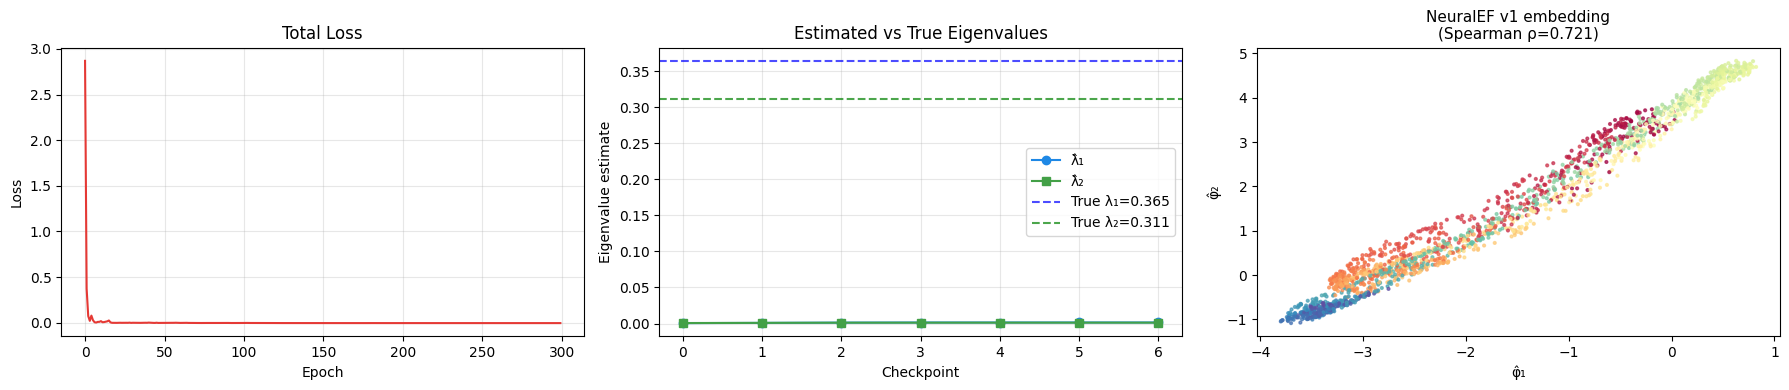


True top-6 eigenvalues: [1.     0.3645 0.311  0.2739 0.0996 0.0886]
NeuralEF v1 estimates:  [0.0014 0.0012]
→ Eigenvalue gap: 2 orders of magnitude — spectral-only objective fails to recover shape.


In [15]:
# ── NeuralEF v1 training diagnostics ───────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(hist_v1["loss"], linewidth=1.5, color='#E53935')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Total Loss", fontsize=12)
axes[0].grid(True, alpha=0.3)

# Approximate orth penalty: loss + rayleigh (not separately tracked in v1 — use loss proxy)
axes[1].plot([e[0] for e in hist_v1["evals"]], 'o-', color='#1E88E5', label='λ̂₁')
axes[1].plot([e[1] for e in hist_v1["evals"]], 's-', color='#43A047', label='λ̂₂')
axes[1].axhline(y=evals_full[1], color='b', linestyle='--', alpha=0.7, label=f'True λ₁={evals_full[1]:.3f}')
axes[1].axhline(y=evals_full[2], color='g', linestyle='--', alpha=0.7, label=f'True λ₂={evals_full[2]:.3f}')
axes[1].set_xlabel("Checkpoint"); axes[1].set_ylabel("Eigenvalue estimate")
axes[1].set_title("Estimated vs True Eigenvalues", fontsize=12); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Embedding comparison
ax = axes[2]
ax.scatter(coords_v1[:, 0], coords_v1[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
ax.set_title(f'NeuralEF v1 embedding\n(Spearman ρ={corr_v1:.3f})', fontsize=11)
ax.set_xlabel('φ̂₁'); ax.set_ylabel('φ̂₂')

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig5_6_neuralef_training.pdf', bbox_inches='tight')
plt.show()

print(f"\nTrue top-6 eigenvalues: {evals_full[:6].round(4)}")
if hist_v1["evals"]:
    print(f"NeuralEF v1 estimates:  {hist_v1['evals'][-1].round(4)}")
    print("→ Eigenvalue gap: 2 orders of magnitude — spectral-only objective fails to recover shape.")


### 5.4.2. NeuralEF v2

NeuralEF v2 bổ sung cơ chế deflation để học $K=5$ hàm riêng theo thứ tự. So sánh các biểu diễn; đối chiếu cấu trúc hàm riêng chính xác và ước lượng.


Training NeuralEF v2 (deflation, K=5) on Swiss Roll...
  v2 Epoch 100/400  λ_est=[0.00127 0.00081 0.0005  0.00028 0.00057]
  v2 Epoch 200/400  λ_est=[0.00138 0.00082 0.00051 0.00031 0.00055]
  v2 Epoch 300/400  λ_est=[0.0014  0.00078 0.00053 0.00026 0.00053]
  v2 Epoch 400/400  λ_est=[0.00145 0.00087 0.00049 0.00028 0.00048]


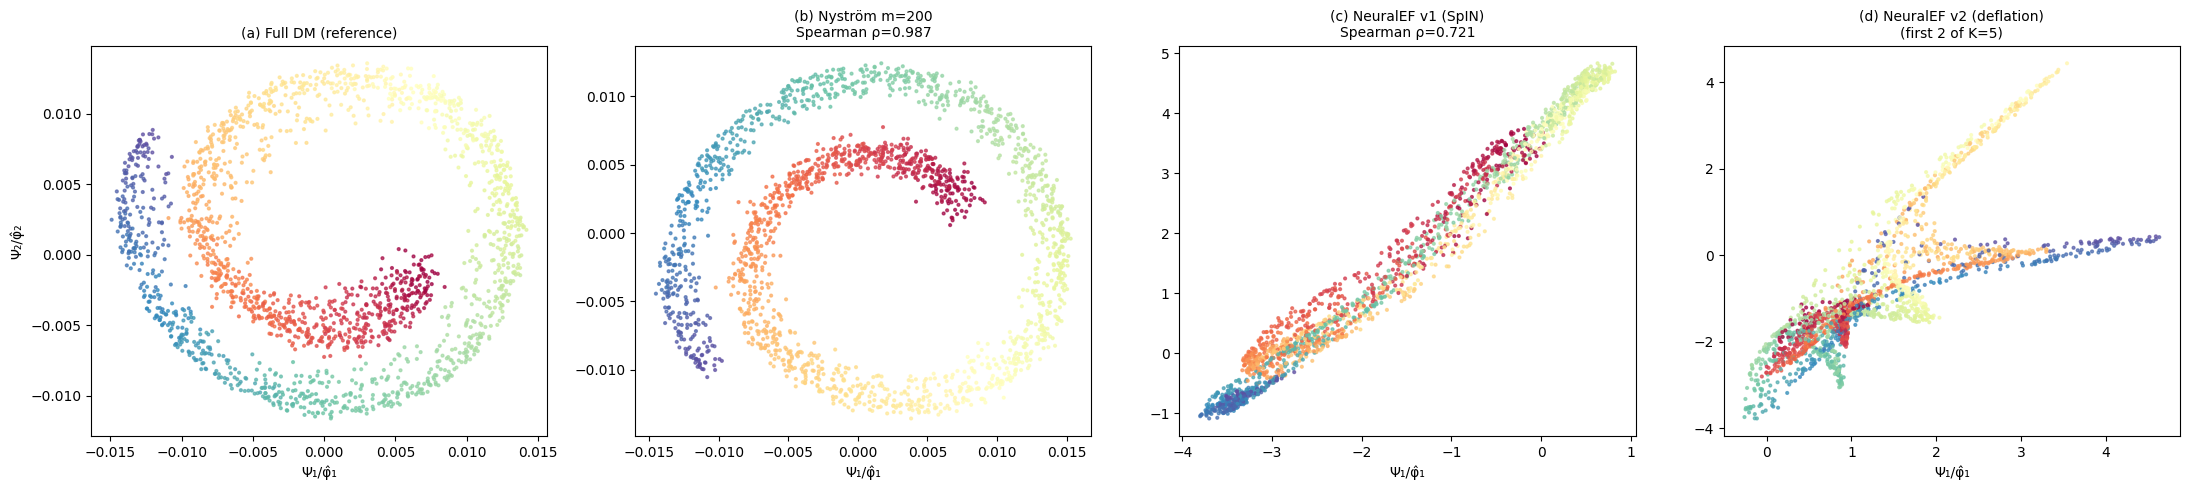

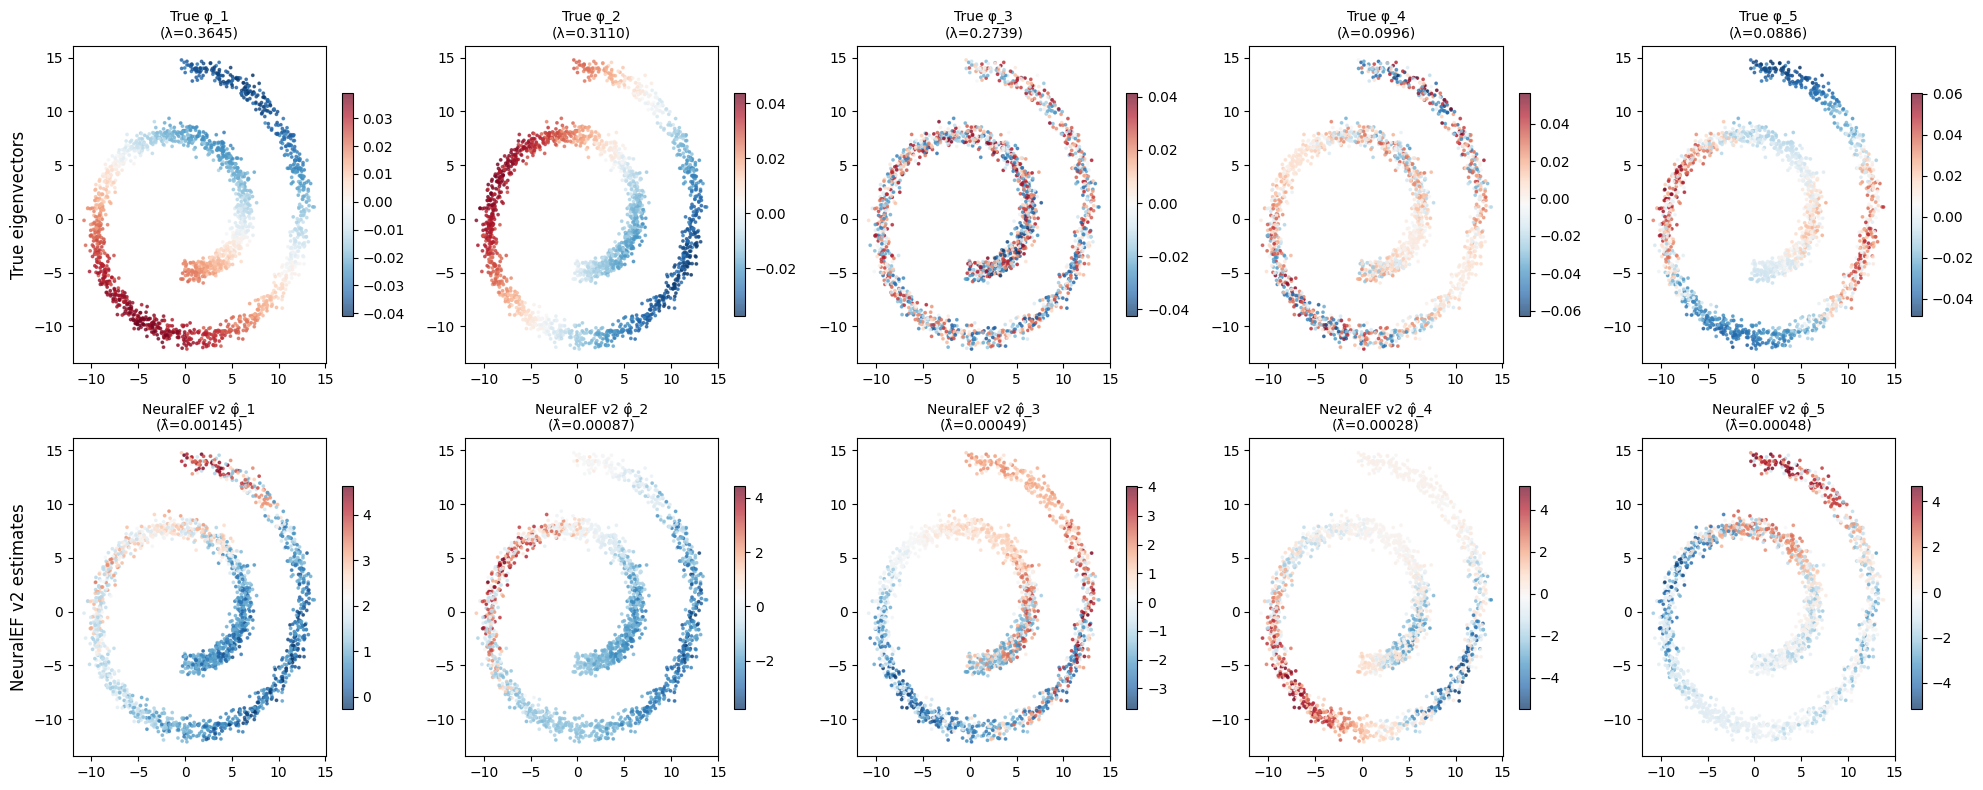


True top-6 eigenvalues:  [0.3645 0.311  0.2739 0.0996 0.0886]
NeuralEF v2 estimates:        [0.00145 0.00087 0.00049 0.00028 0.00048]
→ True eigenfunctions show spatially smooth gradients;
  NeuralEF v2 satisfies orthogonality but produces disordered spatial patterns.


In [17]:
# ── NeuralEF v2 (deflation) — K=5 eigenfunctions ────────────────────────────

class NeuralEFLossV2(nn.Module):
    def __init__(self, n_ef, mu=10.0):
        super().__init__(); self.mu = mu; self.n_ef = n_ef
        self.register_buffer('weights',
            torch.FloatTensor([1.0 / (k + 1) for k in range(n_ef)]))

    def forward(self, F, K_batch):
        B, K = F.shape
        F_norm = F / (F.norm(dim=0, keepdim=True) + 1e-8) * (B ** 0.5)
        G = F_norm.T @ F_norm / B
        FTKF = F_norm.T @ K_batch @ F_norm / (B * B)
        w = self.weights.to(F.device)
        weighted_r = (w * torch.diag(FTKF)).sum()
        orth = ((G - torch.eye(K, device=F.device)) ** 2).sum()
        cross = (FTKF * (1 - torch.eye(K, device=F.device))).pow(2).sum()
        loss = -weighted_r + self.mu * (orth + 0.5 * cross)
        return loss, {"rayleigh_per_ef": torch.diag(FTKF).detach().cpu().numpy(),
                      "orth_penalty": orth.item()}


K_EF = 5
print(f"Training NeuralEF v2 (deflation, K={K_EF}) on Swiss Roll...")
N, D = X_swiss.shape
X_t = torch.FloatTensor(X_swiss).to(device)
loader = DataLoader(TensorDataset(X_t), batch_size=256, shuffle=True, drop_last=True)
model_v2 = NeuralEigenfunction(D, K_EF, [256, 256, 128]).to(device)
crit_v2 = NeuralEFLossV2(K_EF, mu=15.0).to(device)
opt_v2 = optim.Adam(model_v2.parameters(), lr=1e-3, weight_decay=1e-5)
sched_v2 = optim.lr_scheduler.CosineAnnealingLR(opt_v2, T_max=400)
evals_v2_hist = []

for epoch in range(400):
    model_v2.train()
    for (Xb,) in loader:
        Kb = compute_diffusion_kernel_batch(Xb, eps_full)
        F = model_v2(Xb); loss, _ = crit_v2(F, Kb)
        opt_v2.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model_v2.parameters(), 1.0)
        opt_v2.step()
    sched_v2.step()
    if (epoch + 1) % 100 == 0:
        model_v2.eval()
        with torch.no_grad():
            idx = torch.randperm(N)[:512]
            _, ei = crit_v2(model_v2(X_t[idx]), compute_diffusion_kernel_batch(X_t[idx], eps_full))
            evals_v2_hist.append(ei["rayleigh_per_ef"])
        model_v2.train()
        print(f"  v2 Epoch {epoch+1}/400  λ_est={ei['rayleigh_per_ef'].round(5)}")

model_v2.eval()
with torch.no_grad():
    coords_v2 = model_v2(X_t).cpu().numpy()

# ── Fig 5.7: 4-way embedding comparison ─────────────────────────────────────
# Get Nyström m=200
coords_nys_200, _, lm_idx_200, _ = nystrom_diffusion_map(
    X_swiss, m=200, t=1, epsilon=eps_full, landmark_method="kmeans")
err_nys200, corr_nys200 = evaluate_quality(coords_full, coords_nys_200)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (coords, title) in zip(axes, [
    (coords_full,     f'(a) Full DM (reference)'),
    (coords_nys_200,  f'(b) Nyström m=200\nSpearman ρ={corr_nys200:.3f}'),
    (coords_v1,       f'(c) NeuralEF v1 (SpIN)\nSpearman ρ={corr_v1:.3f}'),
    (coords_v2[:, :2],f'(d) NeuralEF v2 (deflation)\n(first 2 of K=5)'),
]):
    ax.scatter(coords[:, 0], coords[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Ψ₁/φ̂₁')
axes[0].set_ylabel('Ψ₂/φ̂₂')
plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_comparison.pdf', bbox_inches='tight')
plt.show()

# ── eigenfunction structure comparison ─────────────────────────────
fig, axes = plt.subplots(2, K_EF, figsize=(4 * K_EF, 8))
for k in range(K_EF):
    ax = axes[0, k]
    sc = ax.scatter(X_swiss[:, 0], X_swiss[:, 2], c=evecs_full[:, k+1], cmap='RdBu_r', s=3, alpha=0.7)
    ax.set_title(f'True φ_{k+1}\n(λ={evals_full[k+1]:.4f})', fontsize=10)
    plt.colorbar(sc, ax=ax, shrink=0.7)

    ax = axes[1, k]
    sc = ax.scatter(X_swiss[:, 0], X_swiss[:, 2], c=coords_v2[:, k], cmap='RdBu_r', s=3, alpha=0.7)
    ev = evals_v2_hist[-1][k] if evals_v2_hist else 0
    ax.set_title(f'NeuralEF v2 φ̂_{k+1}\n(λ̂={ev:.5f})', fontsize=10)
    plt.colorbar(sc, ax=ax, shrink=0.7)

axes[0, 0].set_ylabel('True eigenvectors', fontsize=12)
axes[1, 0].set_ylabel('NeuralEF v2 estimates', fontsize=12)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_eigenfunction_comparison.pdf', bbox_inches='tight')
plt.show()

print(f"\nTrue top-{K_EF+1} eigenvalues:  {evals_full[1:K_EF+1].round(4)}")
if evals_v2_hist:
    print(f"NeuralEF v2 estimates:        {evals_v2_hist[-1].round(5)}")
    print("→ True eigenfunctions show spatially smooth gradients;")
    print("  NeuralEF v2 satisfies orthogonality but produces disordered spatial patterns.")


### 5.4.3. So sánh ngoài mẫu

Nyström và NeuralEF v1 được đánh giá trên cùng phép chia 1.500 mẫu huấn luyện và 500 mẫu kiểm tra của Swiss Roll. Báo cáo thời gian, sai lệch Procrustes và tương quan Spearman.


Training NeuralEF v1 on train split (N=1500)...
  v1 Epoch   1/300  loss=4.0623  λ_est=[0.0007 0.0012]
  v1 Epoch  50/300  loss=0.0063  λ_est=[0.0007 0.0006]
  v1 Epoch 100/300  loss=-0.0023  λ_est=[0.0007 0.0007]
  v1 Epoch 150/300  loss=-0.0029  λ_est=[0.0007 0.0008]
  v1 Epoch 200/300  loss=-0.0030  λ_est=[0.0007 0.0008]
  v1 Epoch 250/300  loss=-0.0033  λ_est=[0.0008 0.0009]
  v1 Epoch 300/300  loss=-0.0033  λ_est=[0.0008 0.0009]

Method               OOS Time       Procrustes ↓   Spearman ρ ↑
──────────────────────────────────────────────────────────────
Nyström (m=200)      2.39ms         0.0422         0.9473
NeuralEF v1          0.82ms         0.1503         0.8151


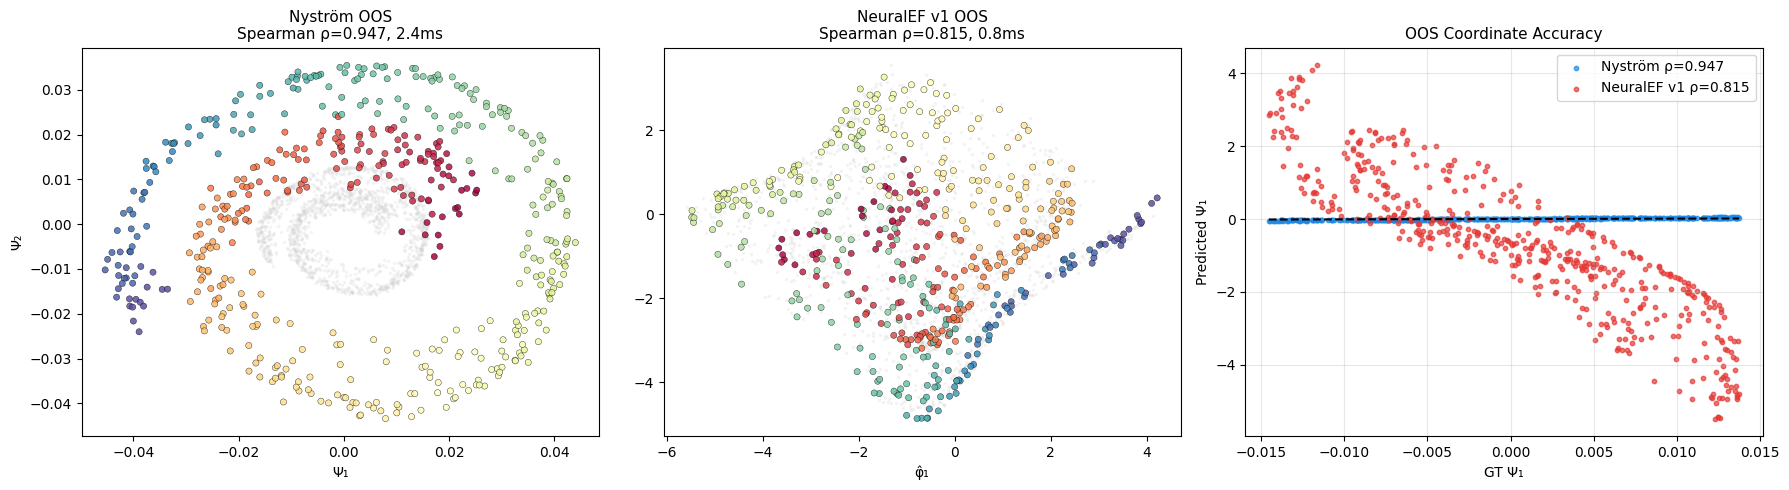

In [18]:
# ── OOS comparison — Nyström vs NeuralEF v1 ────────────────────────

print("Training NeuralEF v1 on train split (N=1500)...")
model_v1_oos, _ = train_neural_ef_v1(X_train_oos, eps_full, n_eigenfunctions=2,
                                      batch_size=256, n_epochs=300, lr=1e-3, mu=10.0)
model_v1_oos.eval()
with torch.no_grad():
    X_test_t = torch.FloatTensor(X_test_oos).to(device)
    t0 = time.time()
    coords_v1_oos = model_v1_oos(X_test_t).cpu().numpy()
    time_v1_oos = time.time() - t0
    coords_v1_train = model_v1_oos(torch.FloatTensor(X_train_oos).to(device)).cpu().numpy()

err_nys_oos, corr_nys_oos = evaluate_quality(coords_test_gt, coords_nys_test)
err_v1_oos,  corr_v1_oos  = evaluate_quality(coords_test_gt, coords_v1_oos)

print(f"\n{'Method':<20} {'OOS Time':<14} {'Procrustes ↓':<14} {'Spearman ρ ↑'}")
print("─" * 62)
print(f"{'Nyström (m=200)':<20} {oos_time*1000:.2f}ms{'':<8} {err_nys_oos:<14.4f} {corr_nys_oos:.4f}")
print(f"{'NeuralEF v1':<20} {time_v1_oos*1000:.2f}ms{'':<8} {err_v1_oos:<14.4f} {corr_v1_oos:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.scatter(coords_nys_train[:, 0], coords_nys_train[:, 1], c='lightgray', s=2, alpha=0.2)
ax.scatter(coords_nys_test[:, 0],  coords_nys_test[:, 1],  c=color_test_oos, cmap='Spectral',
           s=20, edgecolors='black', linewidths=0.3, alpha=0.85)
ax.set_title(f'Nyström OOS\nSpearman ρ={corr_nys_oos:.3f}, {oos_time*1000:.1f}ms', fontsize=11)
ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

ax = axes[1]
ax.scatter(coords_v1_train[:, 0], coords_v1_train[:, 1], c='lightgray', s=2, alpha=0.2)
ax.scatter(coords_v1_oos[:, 0],   coords_v1_oos[:, 1],   c=color_test_oos, cmap='Spectral',
           s=20, edgecolors='black', linewidths=0.3, alpha=0.85)
ax.set_title(f'NeuralEF v1 OOS\nSpearman ρ={corr_v1_oos:.3f}, {time_v1_oos*1000:.1f}ms', fontsize=11)
ax.set_xlabel('φ̂₁')

ax = axes[2]
ax.scatter(coords_test_gt[:, 0], coords_nys_test[:, 0], c='#1E88E5', s=10, alpha=0.7, label=f'Nyström ρ={corr_nys_oos:.3f}')
ax.scatter(coords_test_gt[:, 0], coords_v1_oos[:, 0],   c='#E53935', s=10, alpha=0.7, label=f'NeuralEF v1 ρ={corr_v1_oos:.3f}')
lim = [coords_test_gt[:, 0].min(), coords_test_gt[:, 0].max()]
ax.plot(lim, lim, 'k--', linewidth=1.5)
ax.set_xlabel('GT Ψ₁'); ax.set_ylabel('Predicted Ψ₁')
ax.set_title('OOS Coordinate Accuracy', fontsize=11); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/figneuralef_oos.pdf', bbox_inches='tight')
plt.show()


---
## 5.5. Đánh giá khả năng khái quát

Ba điều kiện được khảo sát trên Swiss Roll: dịch chuyển phân phối, tăng nhiễu và vùng đa tạp chưa xuất hiện trong tập huấn luyện. Cả hai phương pháp sử dụng cùng tập huấn luyện, tập kiểm tra và biểu diễn tham chiếu.


In [19]:
# ═══════════════════════════════════════════════════════════════════════════
# Data preparation for all three generalisation experiments
# ═══════════════════════════════════════════════════════════════════════════

N_tr_gen, N_te_gen = 1500, 500

# ── Experiment 1: Distribution shift ────────────────────────────────────────
X_tr_gen, c_tr_gen = make_swiss_roll(n_samples=N_tr_gen, noise=0.5, random_state=42)
X_te_raw, c_te_gen = make_swiss_roll(n_samples=N_te_gen, noise=0.5, random_state=99)
X_te_gen = X_te_raw * 1.5 + np.array([3, 0, 3])

X_all_gen = np.vstack([X_tr_gen, X_te_gen])
coords_gt_all, _, _, eps_gt_gen = full_diffusion_map(X_all_gen, t=1)
coords_gt_te_gen = coords_gt_all[N_tr_gen:]

coords_nys_tr_gen, lm_gen, _, info_gen = nystrom_diffusion_map(
    X_tr_gen, m=200, t=1, landmark_method="kmeans")
coords_nys_te_gen = nystrom_out_of_sample(X_te_gen, lm_gen, info_gen, t=1)
corr_nys_shift = pairwise_rank_corr(coords_nys_te_gen, coords_gt_te_gen)

print("Training NeuralEF v1 for Exp 1 (Distribution Shift)...")
model_gen1, _ = train_neural_ef_v1(X_tr_gen, eps_gt_gen, n_eigenfunctions=2,
                                    batch_size=256, n_epochs=200, lr=1e-3)
model_gen1.eval()
with torch.no_grad():
    coords_v1_te_gen = model_gen1(torch.FloatTensor(X_te_gen).to(device)).cpu().numpy()
corr_v1_shift = pairwise_rank_corr(coords_v1_te_gen, coords_gt_te_gen)

# ── Experiment 2: Noise robustness ──────────────────────────────────────────
X_clean, c_clean = make_swiss_roll(n_samples=N_tr_gen, noise=0.3, random_state=42)
X_noisy, c_noisy = make_swiss_roll(n_samples=N_te_gen, noise=1.5, random_state=99)

X_all_noise = np.vstack([X_clean, X_noisy])
coords_gt_noise_all, _, _, eps_noise = full_diffusion_map(X_all_noise, t=1)
coords_gt_noisy = coords_gt_noise_all[N_tr_gen:]

coords_nys_clean, lm_noise, _, info_noise = nystrom_diffusion_map(
    X_clean, m=200, t=1, landmark_method="kmeans")
coords_nys_noisy = nystrom_out_of_sample(X_noisy, lm_noise, info_noise, t=1)
corr_nys_noise = pairwise_rank_corr(coords_nys_noisy, coords_gt_noisy)

print("Training NeuralEF v1 for Exp 2 (Noise Robustness)...")
model_gen2, _ = train_neural_ef_v1(X_clean, eps_noise, n_eigenfunctions=2,
                                    batch_size=256, n_epochs=200, lr=1e-3)
model_gen2.eval()
with torch.no_grad():
    coords_v1_noisy = model_gen2(torch.FloatTensor(X_noisy).to(device)).cpu().numpy()
corr_v1_noise = pairwise_rank_corr(coords_v1_noisy, coords_gt_noisy)

# ── Experiment 3: Unseen manifold region ────────────────────────────────────
X_full_exp3, c_full_exp3 = make_swiss_roll(n_samples=N_tr_gen + N_te_gen, noise=0.5, random_state=42)
angle_exp3 = np.arctan2(X_full_exp3[:, 0], X_full_exp3[:, 2])
split_angle = np.percentile(angle_exp3, 60)
train_mask  = angle_exp3 <= split_angle
test_mask   = angle_exp3 >  split_angle

X_half_tr, c_half_tr = X_full_exp3[train_mask][:N_tr_gen], c_full_exp3[train_mask][:N_tr_gen]
X_half_te, c_half_te = X_full_exp3[test_mask][:N_te_gen],  c_full_exp3[test_mask][:N_te_gen]

coords_gt_half_all, _, _, eps_half = full_diffusion_map(np.vstack([X_half_tr, X_half_te]), t=1)
coords_gt_half_te = coords_gt_half_all[len(X_half_tr):]

coords_nys_half_tr, lm_half, _, info_half = nystrom_diffusion_map(
    X_half_tr, m=200, t=1, landmark_method="kmeans")
coords_nys_half_te = nystrom_out_of_sample(X_half_te, lm_half, info_half, t=1)
corr_nys_region = pairwise_rank_corr(coords_nys_half_te, coords_gt_half_te)

print("Training NeuralEF v1 for Exp 3 (Unseen Region)...")
model_gen3, _ = train_neural_ef_v1(X_half_tr, eps_half, n_eigenfunctions=2,
                                    batch_size=256, n_epochs=200, lr=1e-3)
model_gen3.eval()
with torch.no_grad():
    coords_v1_half_te = model_gen3(torch.FloatTensor(X_half_te).to(device)).cpu().numpy()
corr_v1_region = pairwise_rank_corr(coords_v1_half_te, coords_gt_half_te)

print(f"\nExp 1 Distribution Shift:  Nyström={corr_nys_shift:.3f},  NeuralEF v1={corr_v1_shift:.3f}")
print(f"Exp 2 Noise Robustness:    Nyström={corr_nys_noise:.3f},  NeuralEF v1={corr_v1_noise:.3f}")
print(f"Exp 3 Unseen Region:       Nyström={corr_nys_region:.3f},  NeuralEF v1={corr_v1_region:.3f}")


Training NeuralEF v1 for Exp 1 (Distribution Shift)...
  v1 Epoch   1/200  loss=4.4285  λ_est=[0.0013 0.001 ]
  v1 Epoch  50/200  loss=0.0015  λ_est=[0.0008 0.0004]
  v1 Epoch 100/200  loss=-0.0017  λ_est=[0.001  0.0005]
  v1 Epoch 150/200  loss=-0.0031  λ_est=[0.0011 0.0005]
  v1 Epoch 200/200  loss=-0.0033  λ_est=[0.0013 0.0005]
Training NeuralEF v1 for Exp 2 (Noise Robustness)...
  v1 Epoch   1/200  loss=3.9689  λ_est=[0.001  0.0007]
  v1 Epoch  50/200  loss=0.0026  λ_est=[0.0008 0.0006]
  v1 Epoch 100/200  loss=-0.0022  λ_est=[0.0009 0.0007]
  v1 Epoch 150/200  loss=-0.0033  λ_est=[0.001  0.0006]
  v1 Epoch 200/200  loss=-0.0034  λ_est=[0.001  0.0007]
Training NeuralEF v1 for Exp 3 (Unseen Region)...
  v1 Epoch   1/200  loss=5.0083  λ_est=[0.0007 0.0012]
  v1 Epoch  50/200  loss=0.0002  λ_est=[0.0005 0.0009]
  v1 Epoch 100/200  loss=-0.0031  λ_est=[0.0005 0.0011]
  v1 Epoch 150/200  loss=-0.0034  λ_est=[0.0005 0.0013]
  v1 Epoch 200/200  loss=-0.0034  λ_est=[0.0005 0.0012]

Exp 1 D

Các hình trình bày từng điều kiện thực nghiệm. Tổng hợp tương quan Spearman của Nyström và NeuralEF v1.


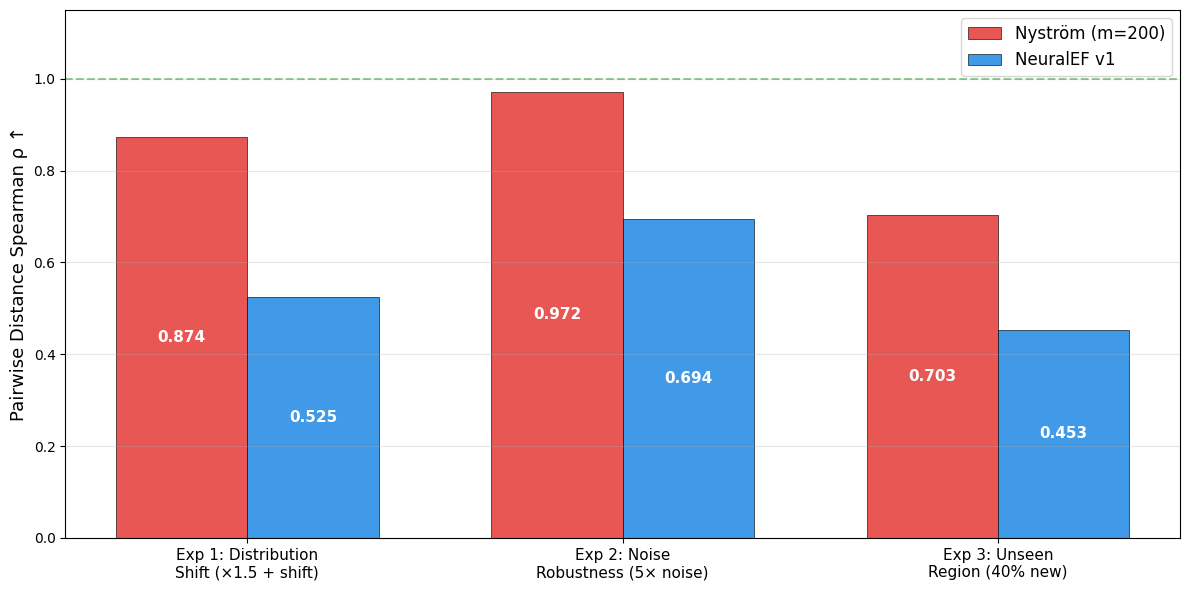


Per-experiment comparison:
  Exp 1: Distribution Shift (×1.5 + shift): Nyström has the higher Spearman correlation.
  Exp 2: Noise Robustness (5× noise): Nyström has the higher Spearman correlation.
  Exp 3: Unseen Region (40% new): Nyström has the higher Spearman correlation.


In [21]:
# ── Generalisation summary bar chart ──────────────────────────────

experiments     = ['Exp 1: Distribution\nShift (×1.5 + shift)',
                   'Exp 2: Noise\nRobustness (5× noise)',
                   'Exp 3: Unseen\nRegion (40% new)']
nys_scores_gen  = [corr_nys_shift, corr_nys_noise, corr_nys_region]
v1_scores_gen   = [corr_v1_shift,  corr_v1_noise,  corr_v1_region]

x = np.arange(len(experiments)); w = 0.35
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - w/2, nys_scores_gen, w, label='Nyström (m=200)', color='#E53935', alpha=0.85, edgecolor='black', lw=0.5)
b2 = ax.bar(x + w/2, v1_scores_gen,  w, label='NeuralEF v1',     color='#1E88E5', alpha=0.85, edgecolor='black', lw=0.5)
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
            f'{bar.get_height():.3f}', ha='center', va='center',
            color='white', fontsize=11, fontweight='bold')

ax.set_ylabel('Pairwise Distance Spearman ρ ↑', fontsize=13)
ax.set_xticks(x); ax.set_xticklabels(experiments, fontsize=11)
ax.legend(fontsize=12); ax.set_ylim(0, 1.15); ax.grid(True, axis='y', alpha=0.3)
ax.axhline(y=1.0, color='green', linestyle='--', alpha=0.4)
plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_gen_summary_v1.pdf', bbox_inches='tight')
import shutil as _shutil
_shutil.copy(f'{_pics}/fig_neuralef_gen_summary_v1.pdf', f'{_pics}/fig5_9_neuralef_generalization.pdf')
plt.show()

print("\nPer-experiment comparison:")
for name, nys_value, neural_value in zip(experiments, nys_scores_gen, v1_scores_gen):
    winner = "Nyström" if nys_value > neural_value else "NeuralEF v1"
    print(f"  {name.replace(chr(10), ' ')}: {winner} has the higher Spearman correlation.")


---
## 5.6. NeuralEF v3

NeuralEF v3 sử dụng mạng dư với GELU, kernel toàn cục và trực giao hóa Cholesky. Các hình trình bày quá trình huấn luyện; đánh giá chất lượng biểu diễn và khả năng khái quát.


In [22]:
# ── NeuralEF v3: Residual MLP + Global Kernel + Cholesky Ortho ──────────────

class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim), nn.LayerNorm(dim), nn.GELU(),
                                 nn.Linear(dim, dim), nn.LayerNorm(dim))
        self.act = nn.GELU()
    def forward(self, x): return self.act(x + self.net(x))


class NeuralEFv3(nn.Module):
    def __init__(self, input_dim, n_eigenfunctions=2, hidden_dim=512, n_blocks=3):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(input_dim, hidden_dim),
                                        nn.LayerNorm(hidden_dim), nn.GELU())
        self.blocks  = nn.Sequential(*[ResidualBlock(hidden_dim) for _ in range(n_blocks)])
        self.output  = nn.Linear(hidden_dim, n_eigenfunctions)

    def forward(self, x): return self.output(self.blocks(self.input_proj(x)))


class NeuralEFLossV3(nn.Module):
    def __init__(self, mu_orth=5.0):
        super().__init__(); self.mu = mu_orth

    def forward(self, F, K_sub):
        B, K = F.shape
        G = F.T @ F / B
        try:
            L = torch.linalg.cholesky(G + 1e-6 * torch.eye(K, device=F.device))
            F_orth = torch.linalg.solve_triangular(L.T, F.T, upper=True).T * (B ** 0.5)
        except Exception:
            F_orth = F / (F.norm(dim=0, keepdim=True) + 1e-8) * (B ** 0.5)
        FTKF = F_orth.T @ K_sub @ F_orth / (B * B)
        evals_d = torch.diag(FTKF)
        weights = torch.FloatTensor([1.0 / (k+1) for k in range(K)]).to(F.device)
        rayleigh = torch.trace(FTKF)
        orth_err = ((F_orth.T @ F_orth / B - torch.eye(K, device=F.device)) ** 2).sum()
        loss = -(weights * evals_d).sum() + self.mu * orth_err
        return loss, {"rayleigh": rayleigh.item(), "orth_error": orth_err.item(),
                      "eigenvalues_est": evals_d.detach().cpu().numpy()}


def precompute_global_kernel(X, eps):
    Xt = torch.FloatTensor(X).to(device)
    dsq = torch.cdist(Xt, Xt, p=2) ** 2
    K   = torch.exp(-dsq / eps)
    d   = 1.0 / torch.sqrt(K.sum(dim=1) + 1e-10)
    return d.unsqueeze(1) * K * d.unsqueeze(0)


def train_neural_ef_v3(X_data, epsilon, n_eigenfunctions=2,
                       batch_size=512, n_epochs=800, lr=3e-4, mu_orth=5.0):
    N, D = X_data.shape
    Xt = torch.FloatTensor(X_data).to(device)
    print(f"  Pre-computing global {N}×{N} kernel...")
    K_global = precompute_global_kernel(X_data, epsilon)
    model = NeuralEFv3(D, n_eigenfunctions, hidden_dim=512, n_blocks=4).to(device)
    crit  = NeuralEFLossV3(mu_orth)
    opt   = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=100, T_mult=2)
    hist  = {"loss": [], "rayleigh": [], "orth": [], "evals": []}
    for epoch in range(n_epochs):
        model.train()
        idx  = torch.randperm(N, device=device)[:batch_size]
        F    = model(Xt[idx])
        loss, info = crit(F, K_global[idx][:, idx])
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(epoch)
        hist["loss"].append(loss.item())
        hist["rayleigh"].append(info["rayleigh"])
        hist["orth"].append(info["orth_error"])
        if (epoch + 1) % 200 == 0 or epoch == 0:
            model.eval()
            with torch.no_grad():
                ei_idx = torch.randperm(N, device=device)[:min(800, N)]
                _, ei = crit(model(Xt[ei_idx]), K_global[ei_idx][:, ei_idx])
                hist["evals"].append(ei["eigenvalues_est"])
            model.train()
            print(f"  v3 Epoch {epoch+1:4d}/{n_epochs}  loss={loss.item():.4f}  "
                  f"rayleigh={info['rayleigh']:.4f}  orth={info['orth_error']:.6f}")
    return model, hist


print("=" * 65)
print("Training NeuralEF v3 (Residual MLP + Global Kernel)")
print("=" * 65)
model_v3, hist_v3 = train_neural_ef_v3(X_swiss, eps_full, n_eigenfunctions=2,
                                        batch_size=512, n_epochs=800, lr=3e-4, mu_orth=5.0)
model_v3.eval()
with torch.no_grad():
    coords_v3 = model_v3(torch.FloatTensor(X_swiss).to(device)).cpu().numpy()
err_v3, corr_v3 = evaluate_quality(coords_full, coords_v3)
print(f"\nNeuralEF v3: Procrustes={err_v3:.4f},  Spearman ρ={corr_v3:.4f}")


Training NeuralEF v3 (Residual MLP + Global Kernel)
  Pre-computing global 2000×2000 kernel...
  v3 Epoch    1/800  loss=554949504.0000  rayleigh=4.5976  orth=110989904.000000
  v3 Epoch  200/800  loss=2611212.7500  rayleigh=0.3340  orth=522242.625000
  v3 Epoch  400/800  loss=2611223.5000  rayleigh=0.3293  orth=522244.750000
  v3 Epoch  600/800  loss=2611210.2500  rayleigh=0.3286  orth=522242.125000
  v3 Epoch  800/800  loss=2611212.5000  rayleigh=0.3327  orth=522242.531250

NeuralEF v3: Procrustes=0.5598,  Spearman ρ=0.6368


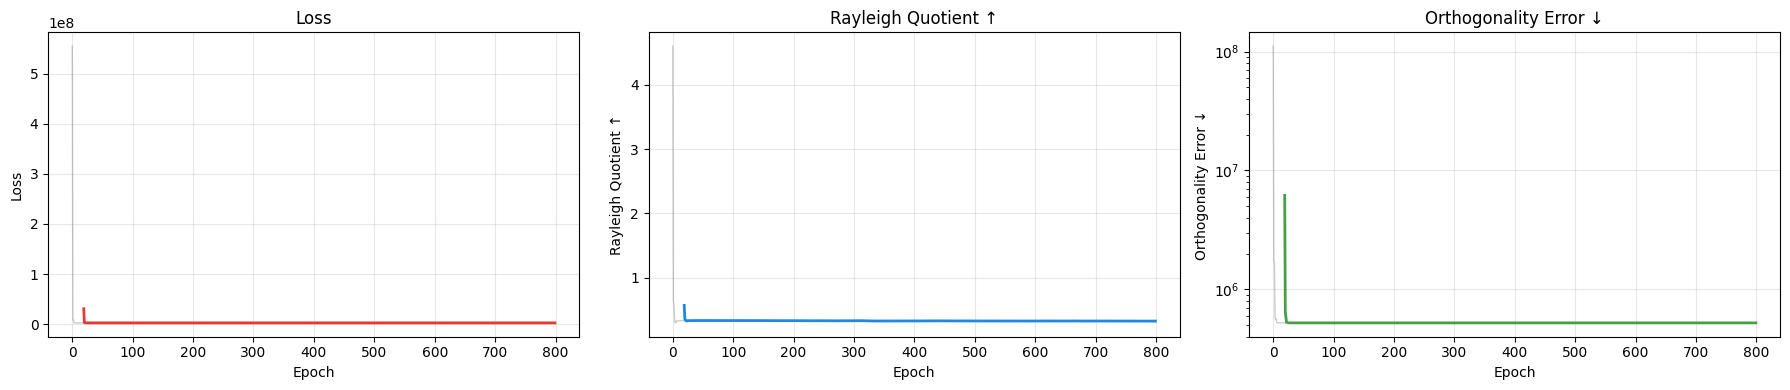

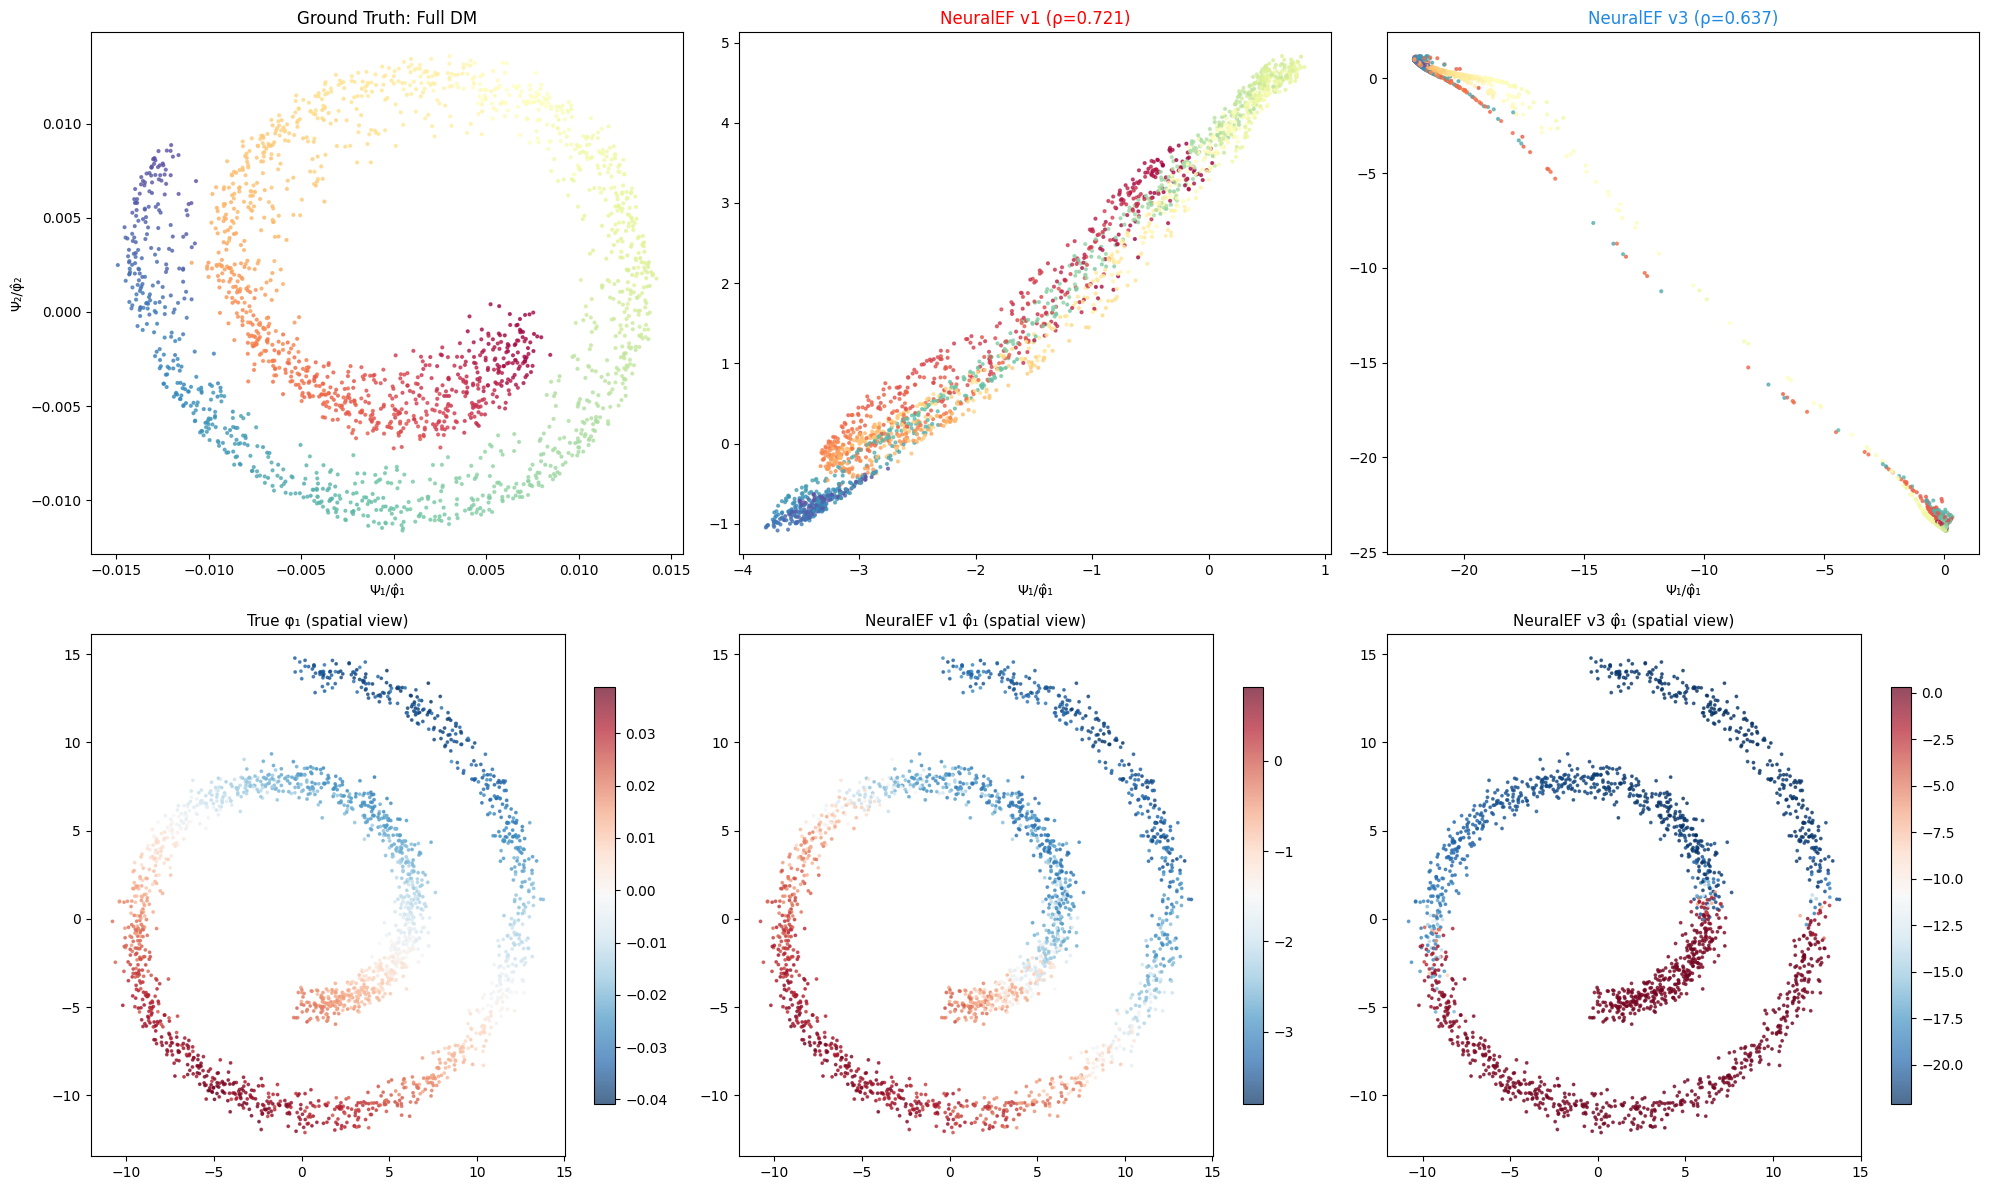

In [23]:
# ── v3 training diagnostics ───────────────────────────────────────

window = 20
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax_i, (data, label, color, yscale) in zip(axes, [
    (hist_v3["loss"],    "Loss",             "#E53935", "linear"),
    (hist_v3["rayleigh"],"Rayleigh Quotient ↑","#1E88E5", "linear"),
    (hist_v3["orth"],    "Orthogonality Error ↓","#43A047","log"),
]):
    ax_i.plot(data, linewidth=1, alpha=0.4, color="gray")
    if len(data) > window:
        sm = np.convolve(data, np.ones(window)/window, mode='valid')
        ax_i.plot(range(window-1, len(data)), sm, linewidth=2, color=color)
    ax_i.set_xlabel("Epoch"); ax_i.set_ylabel(label)
    ax_i.set_title(label, fontsize=12); ax_i.set_yscale(yscale); ax_i.grid(True, alpha=0.3)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_v3_training.pdf', bbox_inches='tight')
plt.show()

# ── Fig 5.16: Shape quality — v1 vs v3 ──────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax_i, (coords, title, col) in zip(axes[0], [
    (coords_full, 'Ground Truth: Full DM',                         None),
    (coords_v1,   f'NeuralEF v1 (ρ={corr_v1:.3f})',               'red'),
    (coords_v3,   f'NeuralEF v3 (ρ={corr_v3:.3f})',               '#1E88E5'),
]):
    ax_i.scatter(coords[:, 0], coords[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
    ax_i.set_title(title, fontsize=12, color=col or 'black')
    ax_i.set_xlabel('Ψ₁/φ̂₁')
axes[0][0].set_ylabel('Ψ₂/φ̂₂')

for ax_i, (method_coords, method, color_code) in zip(axes[1], [
    (evecs_full[:, 1], 'True φ₁',       '#2E7D32'),
    (coords_v1[:, 0],  'NeuralEF v1 φ̂₁','red'),
    (coords_v3[:, 0],  'NeuralEF v3 φ̂₁','#1E88E5'),
]):
    sign = np.sign(pearsonr(evecs_full[:, 1], method_coords)[0])
    sc = ax_i.scatter(X_swiss[:, 0], X_swiss[:, 2], c=sign*method_coords,
                      cmap='RdBu_r', s=3, alpha=0.7)
    ax_i.set_title(f'{method} (spatial view)', fontsize=11); plt.colorbar(sc, ax=ax_i, shrink=0.8)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_v1_vs_v3_shape.pdf', bbox_inches='tight')
plt.show()


Training NeuralEF v3 for all 3 generalization experiments...
  Pre-computing global 1500×1500 kernel...
  v3 Epoch    1/600  loss=3039021.7500  rayleigh=0.4315  orth=607804.375000
  v3 Epoch  200/600  loss=2611215.0000  rayleigh=0.4266  orth=522243.031250
  v3 Epoch  400/600  loss=2611306.2500  rayleigh=0.4263  orth=522261.312500
  v3 Epoch  600/600  loss=2611211.2500  rayleigh=0.4196  orth=522242.312500
  Pre-computing global 1500×1500 kernel...
  v3 Epoch    1/600  loss=5250441.0000  rayleigh=0.3138  orth=1050088.250000
  v3 Epoch  200/600  loss=2611209.2500  rayleigh=0.4292  orth=522241.906250
  v3 Epoch  400/600  loss=2611263.2500  rayleigh=0.4256  orth=522252.687500
  v3 Epoch  600/600  loss=2611210.5000  rayleigh=0.4145  orth=522242.156250
  Pre-computing global 1200×1200 kernel...
  v3 Epoch    1/600  loss=4379254.0000  rayleigh=0.5225  orth=875850.875000
  v3 Epoch  200/600  loss=2611269.7500  rayleigh=0.5816  orth=522254.062500
  v3 Epoch  400/600  loss=2611210.5000  rayleigh=

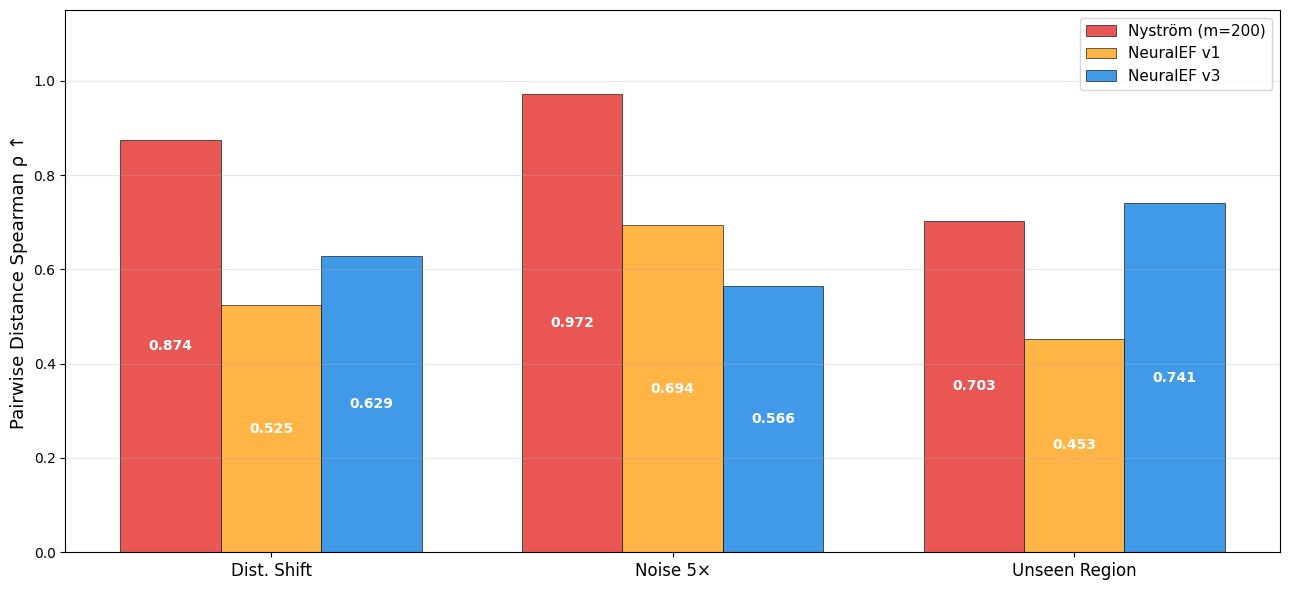


Experiment              Nyström         v1         v3
────────────────────────────────────────────────────
  Distribution Shift     0.8739     0.5245     0.6288
  Noise Robustness       0.9721     0.6944     0.5658
  Unseen Region          0.7034     0.4533     0.7406


In [24]:
# ──  Generalisation with v3 ────────────────────────────────────────

print("Training NeuralEF v3 for all 3 generalization experiments...")

# Exp 1
model_v3_g1, _ = train_neural_ef_v3(X_tr_gen, eps_gt_gen, n_eigenfunctions=2,
                                     batch_size=512, n_epochs=600, lr=3e-4)
model_v3_g1.eval()
with torch.no_grad():
    coords_v3_shift = model_v3_g1(torch.FloatTensor(X_te_gen).to(device)).cpu().numpy()
corr_v3_shift = pairwise_rank_corr(coords_v3_shift, coords_gt_te_gen)

# Exp 2
model_v3_g2, _ = train_neural_ef_v3(X_clean, eps_noise, n_eigenfunctions=2,
                                     batch_size=512, n_epochs=600, lr=3e-4)
model_v3_g2.eval()
with torch.no_grad():
    coords_v3_noise = model_v3_g2(torch.FloatTensor(X_noisy).to(device)).cpu().numpy()
corr_v3_noise = pairwise_rank_corr(coords_v3_noise, coords_gt_noisy)

# Exp 3
model_v3_g3, _ = train_neural_ef_v3(X_half_tr, eps_half, n_eigenfunctions=2,
                                     batch_size=512, n_epochs=600, lr=3e-4)
model_v3_g3.eval()
with torch.no_grad():
    coords_v3_region = model_v3_g3(torch.FloatTensor(X_half_te).to(device)).cpu().numpy()
corr_v3_region = pairwise_rank_corr(coords_v3_region, coords_gt_half_te)

v3_scores = [corr_v3_shift, corr_v3_noise, corr_v3_region]

# Bar chart
exps_short = ['Dist. Shift', 'Noise 5×', 'Unseen Region']
x = np.arange(3); w = 0.25
fig, ax = plt.subplots(figsize=(13, 6))
b1 = ax.bar(x - w, nys_scores_gen, w, label='Nyström (m=200)', color='#E53935', alpha=0.85, edgecolor='black', lw=0.5)
b2 = ax.bar(x,     v1_scores_gen,  w, label='NeuralEF v1',     color='#FFA726', alpha=0.85, edgecolor='black', lw=0.5)
b3 = ax.bar(x + w, v3_scores,      w, label='NeuralEF v3',     color='#1E88E5', alpha=0.85, edgecolor='black', lw=0.5)
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                f'{bar.get_height():.3f}', ha='center', va='center',
                color='white', fontsize=10, fontweight='bold')
ax.set_ylabel('Pairwise Distance Spearman ρ ↑', fontsize=13)
ax.set_xticks(x); ax.set_xticklabels(exps_short, fontsize=12)
ax.legend(fontsize=11); ax.set_ylim(0, 1.15); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_v3_generalization.pdf', bbox_inches='tight')
plt.show()

print(f"\n{'Experiment':<20} {'Nyström':>10} {'v1':>10} {'v3':>10}")
print("─" * 52)
for i, exp in enumerate(['Distribution Shift', 'Noise Robustness', 'Unseen Region']):
    print(f"  {exp:<18} {nys_scores_gen[i]:>10.4f} {v1_scores_gen[i]:>10.4f} {v3_scores[i]:>10.4f}")


---
## 5.7. NeuralEF v4

NeuralEF v4 hồi quy trực tiếp lên các vectơ riêng tham chiếu và bổ sung điều chuẩn phổ:

$$\mathcal{L}_{\mathrm{v4}}=\alpha\,\operatorname{MSE}\!\left(f_\theta(x_i),\phi^*(x_i)\right)+\beta\,\mathcal{L}_{\mathrm{spectral}}.$$

Kiến trúc và các tham số huấn luyện được giữ nguyên từ notebook nguồn. Kết quả được trình bày trong các hình bên dưới.


In [25]:
# ── NeuralEF v4: Eigenfunction Distillation ──────────────────────────────────

class NeuralEFv4(nn.Module):
    """Distillation-based NeuralEF: regress exact eigenvectors."""
    def __init__(self, input_dim, n_eigenfunctions=2, hidden_dim=512, n_blocks=4):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(input_dim, hidden_dim),
                                        nn.LayerNorm(hidden_dim), nn.GELU())
        self.blocks  = nn.Sequential(*[ResidualBlock(hidden_dim) for _ in range(n_blocks)])
        self.output  = nn.Linear(hidden_dim, n_eigenfunctions)

    def forward(self, x): return self.output(self.blocks(self.input_proj(x)))


def train_neural_ef_v4(X_data, true_eigenvectors, epsilon,
                       n_eigenfunctions=2, n_epochs=1500, lr=3e-4,
                       alpha=1.0, beta=0.05, mu_orth=2.0):
    """
    NeuralEF v4: MSE regression onto exact eigenvectors + spectral regularisation.
    Loss = α·MSE(f_θ(x), φ*(x)) + β·L_spectral(f_θ)
    """
    N, D = X_data.shape
    Xt    = torch.FloatTensor(X_data).to(device)
    target = torch.FloatTensor(true_eigenvectors[:, 1:n_eigenfunctions+1]).to(device)

    print(f"  Pre-computing global {N}×{N} kernel...")
    K_global = precompute_global_kernel(X_data, epsilon)

    model = NeuralEFv4(D, n_eigenfunctions, hidden_dim=512, n_blocks=4).to(device)
    crit_spec = NeuralEFLossV3(mu_orth)
    opt   = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    hist  = {"mse": [], "spec": [], "total": [], "evals": []}

    batch_size = min(512, N)
    for epoch in range(n_epochs):
        model.train()
        idx  = torch.randperm(N, device=device)[:batch_size]
        Xb   = Xt[idx]; tgt = target[idx]

        F      = model(Xb)
        mse_loss  = nn.functional.mse_loss(F, tgt)
        K_sub     = K_global[idx][:, idx]
        spec_loss, spec_info = crit_spec(F, K_sub)
        total_loss = alpha * mse_loss + beta * spec_loss

        opt.zero_grad(); total_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()

        hist["mse"].append(mse_loss.item())
        hist["spec"].append(spec_loss.item())
        hist["total"].append(total_loss.item())

        if (epoch + 1) % 300 == 0 or epoch == 0:
            model.eval()
            with torch.no_grad():
                _, si = crit_spec(model(Xt[:min(800, N)]), K_global[:min(800, N)][:, :min(800, N)])
                hist["evals"].append(si["eigenvalues_est"])
            model.train()
            print(f"  v4 Epoch {epoch+1:4d}/{n_epochs}  MSE={mse_loss.item():.5f}  "
                  f"spec={spec_loss.item():.4f}  total={total_loss.item():.5f}")
    return model, hist


print("=" * 65)
print("Training NeuralEF v4 (Distillation from exact eigenvectors)")
print("=" * 65)
model_v4, hist_v4 = train_neural_ef_v4(
    X_swiss, evecs_full, eps_full, n_eigenfunctions=2,
    n_epochs=1500, lr=3e-4, alpha=1.0, beta=0.05, mu_orth=2.0
)
model_v4.eval()
with torch.no_grad():
    coords_v4 = model_v4(torch.FloatTensor(X_swiss).to(device)).cpu().numpy()

err_v4, corr_v4 = evaluate_quality(coords_full, coords_v4)
pearson_v4 = abs(pearsonr(evecs_full[:, 1], coords_v4[:, 0])[0])
print(f"\nNeuralEF v4: Procrustes={err_v4:.4f},  Spearman ρ={corr_v4:.4f},  Pearson={pearson_v4:.4f}")


Training NeuralEF v4 (Distillation from exact eigenvectors)
  Pre-computing global 2000×2000 kernel...
  v4 Epoch    1/1500  MSE=0.35521  spec=1130674.1250  total=56534.06250
  v4 Epoch  300/1500  MSE=0.83323  spec=1044511.4375  total=52226.40625
  v4 Epoch  600/1500  MSE=0.26844  spec=1044500.5000  total=52225.29688
  v4 Epoch  900/1500  MSE=0.03647  spec=1044437.0000  total=52221.88672
  v4 Epoch 1200/1500  MSE=0.00297  spec=1046744.8125  total=52337.24609
  v4 Epoch 1500/1500  MSE=0.00060  spec=1012320.5000  total=50616.02734

NeuralEF v4: Procrustes=0.9968,  Spearman ρ=0.0330,  Pearson=0.0108


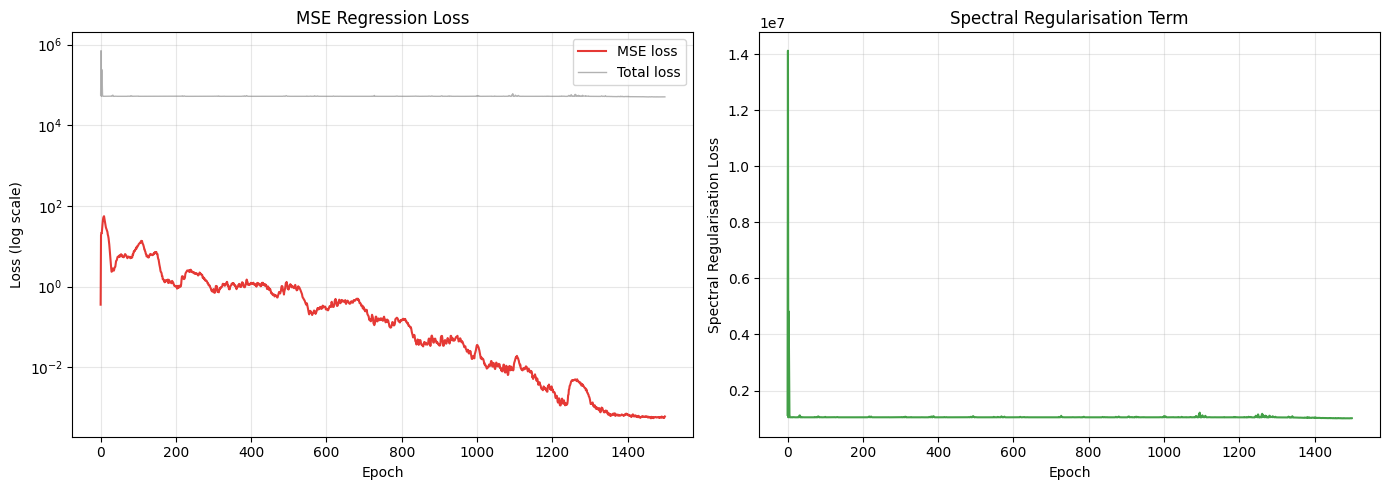

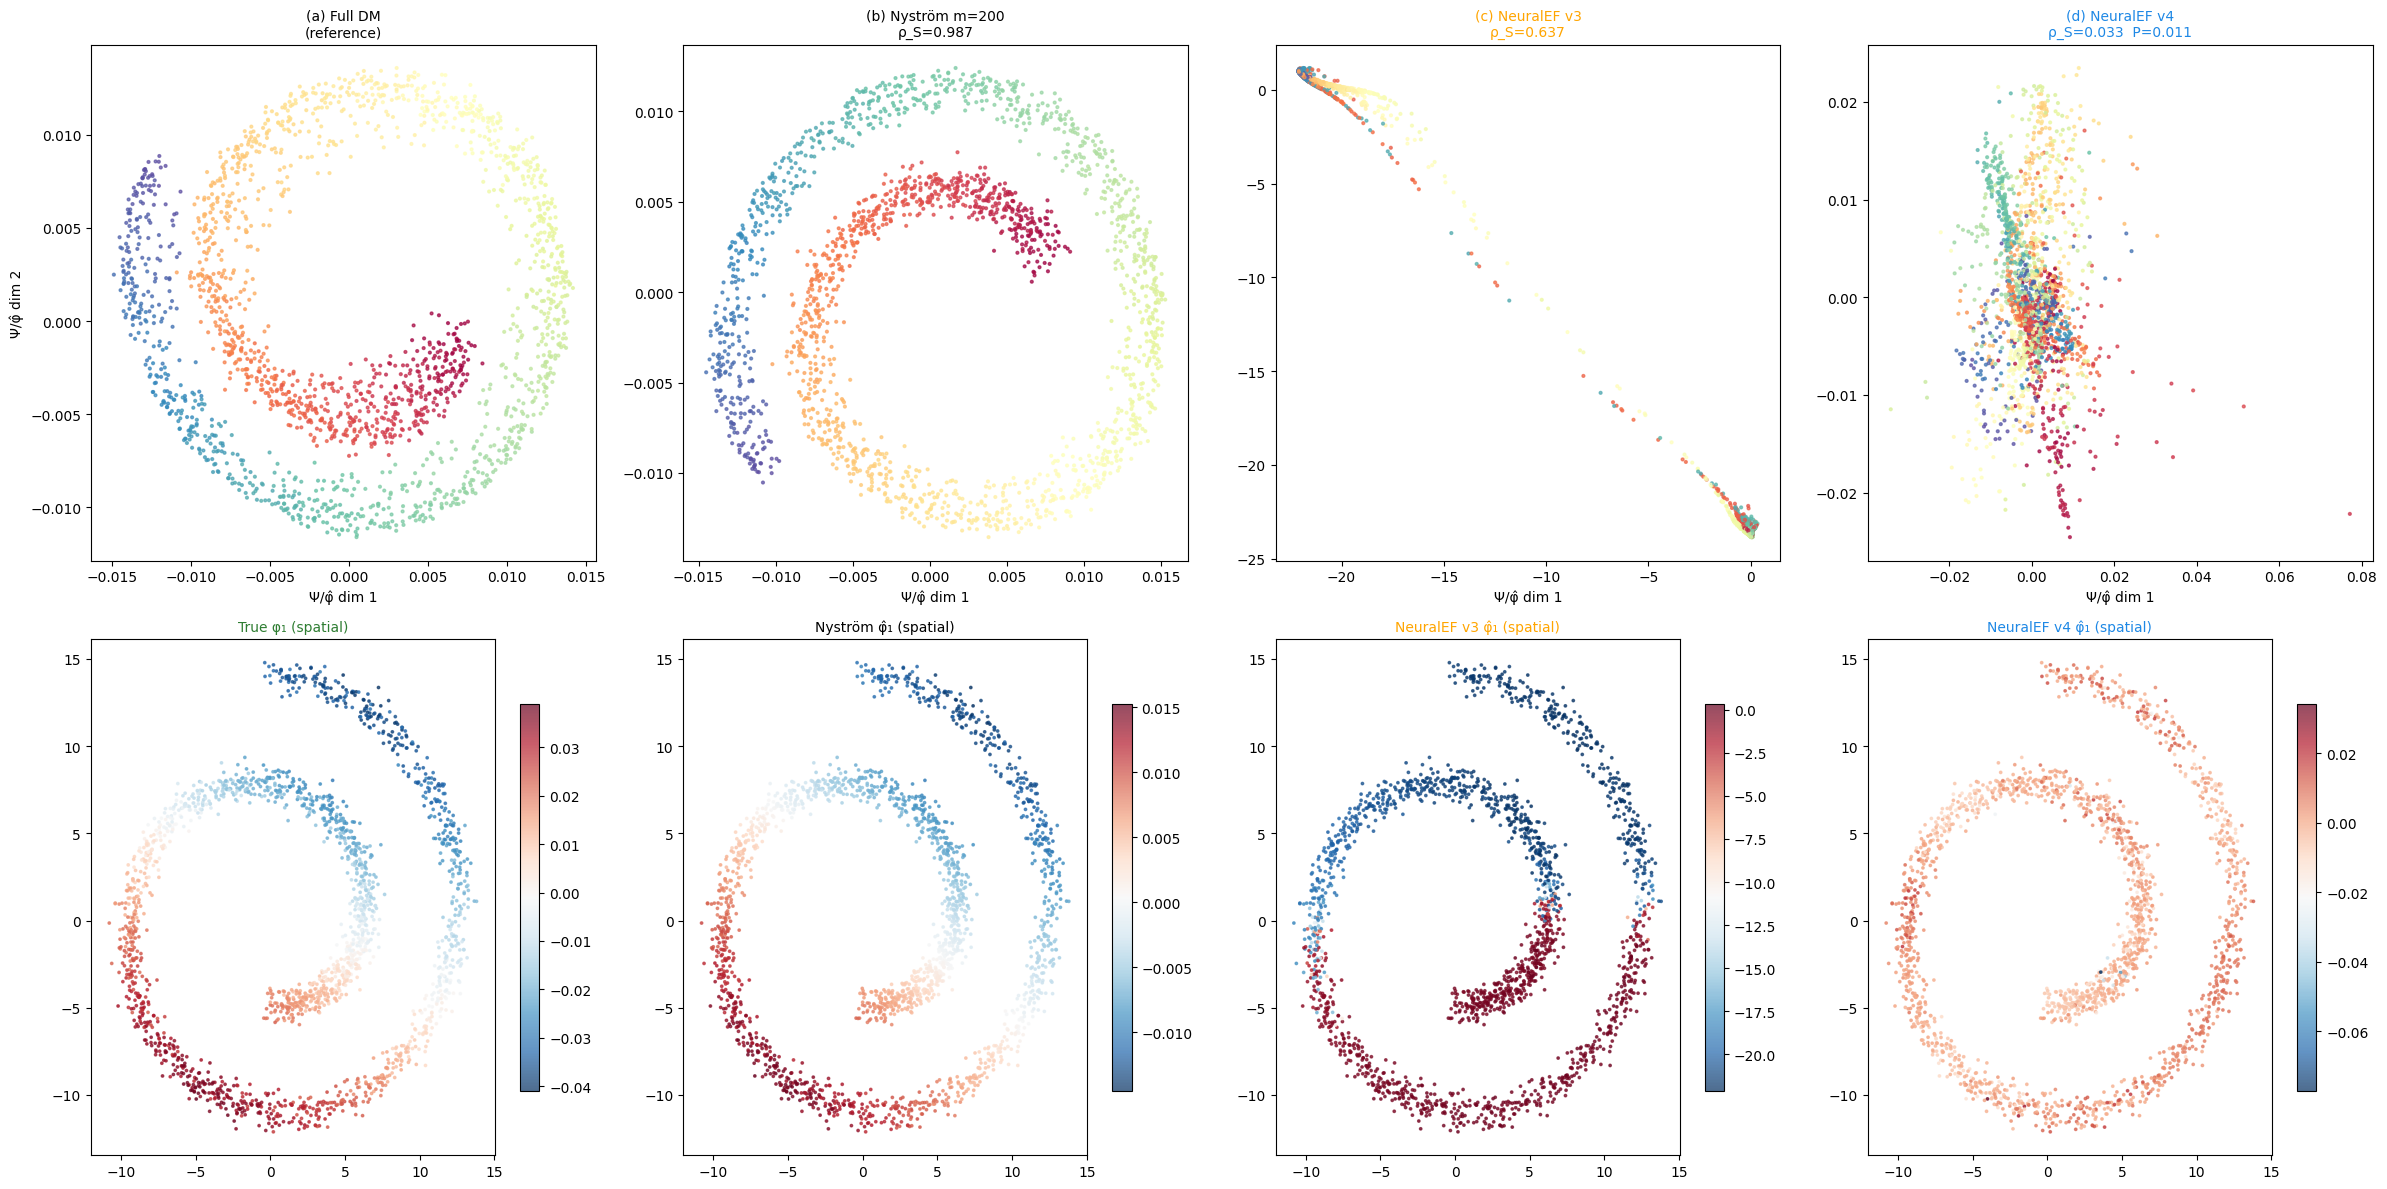


In-sample summary:
Method                    Procrustes ↓    Spearman ρ ↑    Pearson ↑
────────────────────────────────────────────────────────────
  Full DM                 0.0000          1.0000          1.0000
  Nyström m=200           0.0101          0.9872          0.9875
  NeuralEF v1             0.4286          0.7209          0.9607
  NeuralEF v3             0.5598          0.6368          0.7624
  NeuralEF v4             0.9968          0.0330          0.0108


In [26]:
# ── v4 training diagnostics ───────────────────────────────────────

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.semilogy(hist_v4["mse"],   linewidth=1.5, color='#E53935', label='MSE loss')
ax1.semilogy(hist_v4["total"], linewidth=1,   color='gray',    label='Total loss', alpha=0.6)
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss (log scale)")
ax1.set_title("MSE Regression Loss", fontsize=12)
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(hist_v4["spec"], linewidth=1.5, color='#43A047')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Spectral Regularisation Loss")
ax2.set_title("Spectral Regularisation Term", fontsize=12); ax2.grid(True, alpha=0.3)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_v4_training.pdf', bbox_inches='tight')
plt.show()

# ── Shape fidelity — all four methods ──────────────────────────────

fig, axes = plt.subplots(2, 4, figsize=(24, 12))
methods = [
    (coords_full,  f'(a) Full DM\n(reference)',              None),
    (coords_nys_200, f'(b) Nyström m=200\nρ_S={corr_nys200:.3f}', None),
    (coords_v3,    f'(c) NeuralEF v3\nρ_S={corr_v3:.3f}',   'orange'),
    (coords_v4,    f'(d) NeuralEF v4\nρ_S={corr_v4:.3f}  P={pearson_v4:.3f}', '#1E88E5'),
]
for ax_i, (coords, title, col) in zip(axes[0], methods):
    ax_i.scatter(coords[:, 0], coords[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
    ax_i.set_title(title, fontsize=10, color=col or 'black')
    ax_i.set_xlabel('Ψ/φ̂ dim 1')
axes[0][0].set_ylabel('Ψ/φ̂ dim 2')

ef_methods = [
    (evecs_full[:, 1], 'True φ₁',       '#2E7D32'),
    (coords_nys_200[:, 0], 'Nyström φ̂₁', None),
    (coords_v3[:, 0],  'NeuralEF v3 φ̂₁','orange'),
    (coords_v4[:, 0],  'NeuralEF v4 φ̂₁','#1E88E5'),
]
for ax_i, (vals, title, col) in zip(axes[1], ef_methods):
    sign = np.sign(pearsonr(evecs_full[:, 1], vals)[0])
    sc = ax_i.scatter(X_swiss[:, 0], X_swiss[:, 2], c=sign*vals, cmap='RdBu_r', s=3, alpha=0.7)
    ax_i.set_title(f'{title} (spatial)', fontsize=10, color=col or 'black')
    plt.colorbar(sc, ax=ax_i, shrink=0.75)

plt.tight_layout()
_pics = '/content/pictures'
plt.savefig(f'{_pics}/fig_neuralef_v4_shape.pdf', bbox_inches='tight')
plt.show()

print("\nIn-sample summary:")
print(f"{'Method':<25} {'Procrustes ↓':<15} {'Spearman ρ ↑':<15} {'Pearson ↑'}")
print("─" * 60)
for name, c, e in [
    ('Full DM',            coords_full,    (0.000, 1.000)),
    ('Nyström m=200',      coords_nys_200, evaluate_quality(coords_full, coords_nys_200)),
    ('NeuralEF v1',        coords_v1,      (err_v1, corr_v1)),
    ('NeuralEF v3',        coords_v3,      (err_v3, corr_v3)),
    ('NeuralEF v4',        coords_v4,      (err_v4, corr_v4)),
]:
    p = abs(pearsonr(evecs_full[:, 1], c[:, 0])[0]) if name != 'Full DM' else 1.0
    print(f"  {name:<23} {e[0]:<15.4f} {e[1]:<15.4f} {p:.4f}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Running 2-dataset unseen-region benchmark...
  Pre-computing global 1200×1200 kernel...
  v3 Epoch    1/500  loss=56626288.0000  rayleigh=1.6242  orth=11325258.000000
  v3 Epoch  200/500  loss=2611211.7500  rayleigh=0.5324  orth=522242.406250
  v3 Epoch  400/500  loss=2611210.7500  rayleigh=0.5290  orth=522242.187500
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/800  MSE=0.80676  spec=1170344.1250  total=58518.01562
  v4 Epoch  300/800  MSE=1.63535  spec=1044488.4375  total=52226.05859
  v4 Epoch  600/800  MSE=0.18411  spec=1044759.3125  total=52238.14844
  Swiss Roll          : Nyström=0.436  v3=0.534  v4=0.854
  Pre-computing global 1200×1200 kernel...
  v3 Epoch    1/500  loss=12406824.0000  rayleigh=0.9640  orth=2481365.000000
  v3 Epoch  200/500  loss=2611209.5000  rayleigh=0.4579  orth=522241.968750
  v3 Epoch  400/500  loss=2611210.0000  rayleigh=0.4538  orth=522242.062500
  Pre-computing global 1200×1200 kernel...


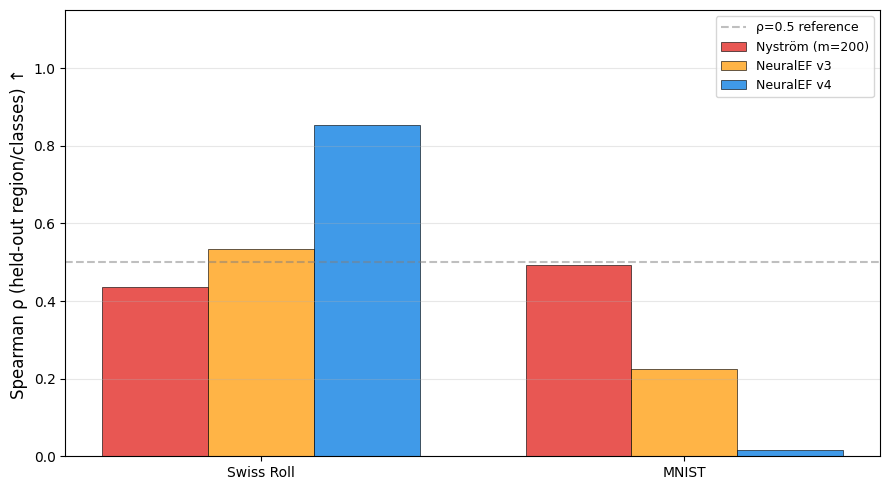


Nyström wins: 1/2   NeuralEF v4 wins: 1/2


In [27]:
# ── Swiss Roll and MNIST unseen-region benchmark ──────────────────

def generate_benchmark_datasets(N=2000, seed=42):
    rng = np.random.RandomState(seed)
    datasets = {}

    X_sr, c_sr = make_swiss_roll(n_samples=N, noise=0.5, random_state=seed)
    order_sr = np.argsort(c_sr)
    datasets["Swiss Roll"] = (X_sr[order_sr], c_sr[order_sr])

    (X_mnist_all, y_mnist_all), _ = mnist.load_data()
    if N % 10 != 0:
        raise ValueError("N must be divisible by 10 for balanced MNIST sampling.")
    n_per_digit = N // 10
    selected = np.concatenate([rng.choice(np.where(y_mnist_all == digit)[0], size=n_per_digit, replace=False) for digit in range(10)])
    X_mnist = X_mnist_all[selected].astype(np.float32).reshape(N, -1) / 255.0
    y_mnist = y_mnist_all[selected].astype(float)
    order_mnist = np.argsort(y_mnist)
    datasets["MNIST"] = (X_mnist[order_mnist], y_mnist[order_mnist])
    return datasets

benchmark_datasets = generate_benchmark_datasets(N=2000, seed=42)
split_frac = 0.6
v3_bench, v4_bench, nys_bench = {}, {}, {}

print(f"Running {len(benchmark_datasets)}-dataset unseen-region benchmark...")
for ds_name, (X_ds, c_ds) in benchmark_datasets.items():
    N_ds = len(X_ds)
    split = int(N_ds * split_frac)
    X_tr_ds, X_te_ds = X_ds[:split], X_ds[split:]

    coords_all_ds, _, evecs_ds, eps_ds = full_diffusion_map(X_ds, t=1)
    coords_gt_te_ds = coords_all_ds[split:]

    cn_tr, lm_ds, _, info_ds = nystrom_diffusion_map(X_tr_ds, m=min(200, split-1), t=1)
    cn_te = nystrom_out_of_sample(X_te_ds, lm_ds, info_ds, t=1)
    nys_bench[ds_name] = pairwise_rank_corr(cn_te, coords_gt_te_ds)

    mv3, _ = train_neural_ef_v3(X_tr_ds, eps_ds, n_eigenfunctions=2, batch_size=512, n_epochs=500, lr=3e-4)
    mv3.eval()
    with torch.no_grad():
        cv3_te = mv3(torch.FloatTensor(X_te_ds).to(device)).cpu().numpy()
    v3_bench[ds_name] = pairwise_rank_corr(cv3_te, coords_gt_te_ds)

    mv4, _ = train_neural_ef_v4(X_tr_ds, evecs_ds[:split], eps_ds, n_eigenfunctions=2, n_epochs=800, lr=3e-4, alpha=1.0, beta=0.05)
    mv4.eval()
    with torch.no_grad():
        cv4_te = mv4(torch.FloatTensor(X_te_ds).to(device)).cpu().numpy()
    v4_bench[ds_name] = pairwise_rank_corr(cv4_te, coords_gt_te_ds)

    print(f"  {ds_name:<20}: Nyström={nys_bench[ds_name]:.3f}  v3={v3_bench[ds_name]:.3f}  v4={v4_bench[ds_name]:.3f}")

ds_names = list(benchmark_datasets.keys())
x = np.arange(len(ds_names)); w = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w, [nys_bench[n] for n in ds_names], w, label='Nyström (m=200)', color='#E53935', alpha=0.85, edgecolor='black', lw=0.5)
b2 = ax.bar(x, [v3_bench[n] for n in ds_names], w, label='NeuralEF v3', color='#FFA726', alpha=0.85, edgecolor='black', lw=0.5)
b3 = ax.bar(x + w, [v4_bench[n] for n in ds_names], w, label='NeuralEF v4', color='#1E88E5', alpha=0.85, edgecolor='black', lw=0.5)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='ρ=0.5 reference')
ax.set_ylabel('Spearman ρ (held-out region/classes) ↑', fontsize=12)
ax.set_xticks(x); ax.set_xticklabels(ds_names, fontsize=10)
ax.legend(fontsize=9); ax.set_ylim(0, 1.15); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{_pics}/fig_two_datasets.pdf', bbox_inches='tight')
plt.show()

v4_wins = sum(v4_bench[n] >= max(nys_bench[n], v3_bench[n]) for n in ds_names)
nys_wins = sum(nys_bench[n] >= max(v3_bench[n], v4_bench[n]) for n in ds_names)
print(f"\nNyström wins: {nys_wins}/{len(ds_names)}   NeuralEF v4 wins: {v4_wins}/{len(ds_names)}")


---
## 5.8. So sánh trên Swiss Roll và MNIST

Benchmark cuối sử dụng đúng hai bộ dữ liệu của nghiên cứu. Swiss Roll được chia theo tham số nội tại; MNIST được lấy mẫu cân bằng và chia theo nhóm chữ số. Tỷ lệ chia, số landmark, kiến trúc mạng và lịch huấn luyện được giữ nguyên.

| Phương pháp | Giai đoạn khớp mô hình | Ánh xạ ngoài mẫu |
|---|---|---|
| Diffusion Maps đầy đủ | Phân rã kernel toàn bộ | Tính lại trên dữ liệu kết hợp |
| Nyström | Phân rã trên $m=200$ landmark | Nội suy kernel từ landmark |
| NeuralEF v3/v4 | Học hàm riêng bằng mạng thần kinh | Truyền xuôi qua mạng |


  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=0.24621  spec=2511228.2500  total=125561.66406
  v4 Epoch  300/500  MSE=0.49233  spec=1044482.6250  total=52224.62500
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=1.06969  spec=1875994.2500  total=93800.78125
  v4 Epoch  300/500  MSE=0.70011  spec=1044920.1875  total=52246.71094
Average Spearman: Nyström=0.4650  v3=0.3791  v4=0.4354
Average Pearson (v4, 2 datasets): 0.0442


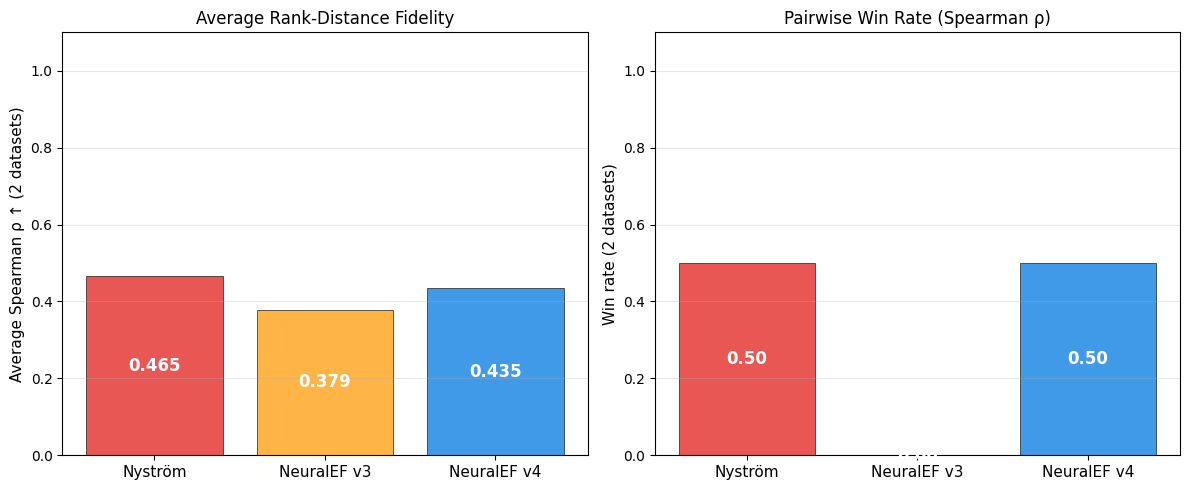

In [28]:
# ── ummary across Swiss Roll and MNIST ───────────────────────────

methods_summary = ['Nyström', 'NeuralEF v3', 'NeuralEF v4']
avg_spearman = [np.mean(list(nys_bench.values())), np.mean(list(v3_bench.values())), np.mean(list(v4_bench.values()))]

pearson_v4_bench = []
for ds_name, (X_ds, c_ds) in benchmark_datasets.items():
    split = int(len(X_ds) * split_frac)
    X_tr_ds = X_ds[:split]
    X_te_ds = X_ds[split:]
    _, _, evecs_ds, eps_ds = full_diffusion_map(X_ds, t=1)
    gt_ef1 = evecs_ds[split:, 1]
    mv4_b, _ = train_neural_ef_v4(X_tr_ds, evecs_ds[:split], eps_ds, n_eigenfunctions=2, n_epochs=500, lr=3e-4, alpha=1.0, beta=0.05)
    mv4_b.eval()
    with torch.no_grad():
        cv4_b = mv4_b(torch.FloatTensor(X_te_ds).to(device)).cpu().numpy()
    pearson_v4_bench.append(abs(pearsonr(gt_ef1, cv4_b[:, 0])[0]))

avg_pearson_v4 = np.mean(pearson_v4_bench)
n_datasets = len(ds_names)
print(f"Average Spearman: Nyström={avg_spearman[0]:.4f}  v3={avg_spearman[1]:.4f}  v4={avg_spearman[2]:.4f}")
print(f"Average Pearson (v4, {n_datasets} datasets): {avg_pearson_v4:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x_s = np.arange(3)
bars = axes[0].bar(x_s, avg_spearman, color=['#E53935', '#FFA726', '#1E88E5'], alpha=0.85, edgecolor='black', lw=0.5)
for bar, val in zip(bars, avg_spearman):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2, f'{val:.3f}', ha='center', va='center', color='white', fontsize=12, fontweight='bold')
axes[0].set_xticks(x_s); axes[0].set_xticklabels(methods_summary, fontsize=11)
axes[0].set_ylabel(f'Average Spearman ρ ↑ ({n_datasets} datasets)', fontsize=11)
axes[0].set_title('Average Rank-Distance Fidelity', fontsize=12)
axes[0].set_ylim(0, 1.1); axes[0].grid(True, axis='y', alpha=0.3)

nys_wins_arr = [int(nys_bench[n] > v3_bench[n] and nys_bench[n] > v4_bench[n]) for n in ds_names]
v3_wins_arr = [int(v3_bench[n] > nys_bench[n] and v3_bench[n] > v4_bench[n]) for n in ds_names]
v4_wins_arr = [int(v4_bench[n] > nys_bench[n] and v4_bench[n] > v3_bench[n]) for n in ds_names]
win_rates = [sum(nys_wins_arr)/n_datasets, sum(v3_wins_arr)/n_datasets, sum(v4_wins_arr)/n_datasets]
bar2 = axes[1].bar(x_s, win_rates, color=['#E53935', '#FFA726', '#1E88E5'], alpha=0.85, edgecolor='black', lw=0.5)
for bar, val in zip(bar2, win_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2, f'{val:.2f}', ha='center', va='center', color='white', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_s); axes[1].set_xticklabels(methods_summary, fontsize=11)
axes[1].set_ylabel(f'Win rate ({n_datasets} datasets)', fontsize=11)
axes[1].set_title('Pairwise Win Rate (Spearman ρ)', fontsize=12)
axes[1].set_ylim(0, 1.1); axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{_pics}/fig_two_datasets_summary.pdf', bbox_inches='tight')
plt.show()


---
## 5.9. Kết luận

Thực nghiệm tập trung vào bài toán ánh xạ ngoài mẫu. Diffusion Maps đầy đủ cung cấp biểu diễn tham chiếu; Nyström mở rộng cấu trúc phổ từ landmark; NeuralEF xây dựng ánh xạ tham số hóa. Hiệu quả của từng phương pháp được kết luận từ kết quả thực thi trên Swiss Roll và MNIST.
